# 5r_ungroup2d: 2D ungrouping (age × time) for the residual net migration of 4r

4r estimates net migration by cohort as a residual (population change + deaths), splitting each year's 5-year population bands into single years separately (`ungroup::pclm`, 1D). A one-year residual subtracts two such splits a year apart. Their errors at band edges therefore turn into **method noise**:
- about ±15–30 per 1,000 for single intervals where neighbouring birth cohorts differ sharply (the 1944–50 births);
- up to ±50 per 1,000 for single municipality × cohort cells in small municipalities.

This notebook tries **`ungroup::pclm2D`**, which fits all years of a municipality at once as a smooth surface over age × time. The question is whether borrowing strength across years makes the single-year splits of consecutive years more consistent, and so reduces the residual noise.

**What changes and what doesn't**
- **Population** is ungrouped with `pclm2D`, one fit per municipality over the whole window:
  - the bands are harmonised to 0–4 … 75–79, 80+ (the top band was 80+ up to 2014);
  - the national single-year shape at each count date is the offset, as in 4r;
  - both smoothing parameters (age, time) are chosen by BIC, with `kr` = 2;
  - the fit is rescaled so every published band total is kept exactly.
- **Deaths and movers** keep the 1D fits from 4r (`output/4r_pclm_cache.qs2`). Smoothing them over time would flatten the 2011 tsunami deaths and the 2016 movers, the spikes we want to measure. Population is a stock and changes smoothly.
- **Everything else is identical to 4r:** death timing (2011 excess in 2011-03-31 → 2012-03-31), the Lexis split, cohorts, groups and periods. So every 1D-vs-2D difference below comes from the population split alone.

**Comparisons**
- Figure 1: single-age residuals in pre-quake years.
- Figure 2: pre-quake noise by age band.
- Figure 3: validation against reported migration (Kumamoto 2014–2020), by cohort and municipality size.
- Figures 4–7: the 4r group figures redone with 2D.
- Figure 8: the Kumamoto age profile laid out like 3r figure 3, reported vs residual net.
- Figures 9–10: what the 2D fits look like for three Kumamoto municipalities.
- Figure 11: 4r figure 6 (residual vs reported, Kumamoto 2014–2020) with the 2D residual.

Figures are written to `res/5r_<NN>_<item>.png`. Run `4r_residual_migration.ipynb` first; this notebook reads its 1D cache.

In [1]:
suppressWarnings(suppressPackageStartupMessages({
  library(dplyr)
  library(tidyr)
  library(ggplot2)
  library(qs2)
  library(ungroup)
}))
options(repr.plot.width = 16, repr.plot.height = 9, repr.plot.res = 110,
        jupyter.plot_mimetypes = "image/png")

root <- if (dir.exists("dt")) "." else ".."
res_dir <- file.path(root, "res")
dir.create(res_dir, showWarnings = FALSE)
surface <- "#fcfcfb"
ink <- "#2b2b29"; ink2 <- "#5c5c58"; ink3 <- "#8a8a85"; grid_col <- "#e6e5e1"
jp_font <- "Noto Sans CJK JP"

nb_prefix <- "5r_"
show_save <- function(p, name, width = 16, height = 9) {
  ggsave(file.path(res_dir, paste0(nb_prefix, name, ".png")), p,
         width = width, height = height, dpi = 150, bg = surface)
  print(p)
  invisible(p)
}
top_age <- 105

base_theme <- function() list(
  theme_minimal(base_size = 10, base_family = jp_font),
  theme(
    plot.background = element_rect(fill = surface, colour = NA),
    panel.grid.minor = element_blank(),
    panel.grid.major.x = element_blank(),
    panel.grid.major.y = element_line(colour = grid_col, linewidth = 0.3),
    panel.spacing = unit(0.5, "cm"),
    strip.text = element_text(face = "bold", hjust = 0, colour = ink, size = 9.5),
    plot.title = element_text(face = "bold", size = 14),
    plot.subtitle = element_text(colour = ink2, size = 10),
    plot.caption = element_text(colour = ink3, size = 8, hjust = 0),
    plot.title.position = "plot",
    plot.caption.position = "plot",
    axis.text = element_text(colour = ink2, size = 8),
    axis.title = element_text(colour = ink2, size = 10),
    legend.position = "top",
    legend.justification = "left",
    legend.text = element_text(size = 10)
  )
)
src_note <- paste0("Population: Basic Resident Register (住民基本台帳), Japanese residents. Deaths: Vital Statistics (人口動態統計), ",
                   "Japanese, by residence. Net migration = residual (population change + deaths).")

# One entry per disaster: population count years (labels as in the 住基 data),
# baseline count and the quake interval (identified by its starting count).
events <- list(
  tohoku   = list(title = "2011 Great East Japan Earthquake", groups = c("東日本", "福島"),
                  counts = 2006:2016, base = 2010, quake_start = 2010),
  kumamoto = list(title = "2016 Kumamoto Earthquake", groups = "熊本",
                  counts = 2011:2021, base = 2016, quake_start = 2016)
)

In [2]:
study <- readxl::read_excel(file.path(root, "dt/analysis_original_data.xlsx"),
                            sheet = "1_市町村一覧", col_types = "text") |>
  filter(災害 %in% c("東日本", "福島", "熊本")) |>
  transmute(event = ifelse(災害 == "熊本", "kumamoto", "tohoku"),
            code = 市町村コード, muni = 市町村, pref = 県, short = sub("^.*郡", "", 市町村),
            zenkai_rate = as.numeric(`全壊率(全壊棟数/人口×100)`),
            evacuation = 避難指示あり %in% c("TRUE", "True", "1")) |>
  mutate(group = case_when(
    event == "tohoku" & pref == "福島県" & evacuation ~ "福島 避難指示 (evacuation order)",
    event == "tohoku" & pref != "福島県" & zenkai_rate >= 1 ~ "岩手・宮城 全壊率 ≥ 1",
    event == "tohoku" ~ "Other listed (Tohoku)",
    zenkai_rate >= 1 ~ "High damage (全壊率 ≥ 1)",
    code == "43100" ~ "熊本市",
    TRUE ~ "Other listed (Kumamoto)"))
group_levels <- list(
  tohoku = c("岩手・宮城 全壊率 ≥ 1", "福島 避難指示 (evacuation order)", "Other listed (Tohoku)"),
  kumamoto = c("High damage (全壊率 ≥ 1)", "熊本市", "Other listed (Kumamoto)"))
group_cols <- c(setNames(c("#eb6834", "#2a78d6", "#1baf7a"), group_levels$tohoku),
                setNames(c("#eb6834", "#2a78d6", "#1baf7a"), group_levels$kumamoto))

study |> count(event, group) |> as.data.frame()
study |> filter(event == "tohoku", zenkai_rate >= 1 | evacuation) |>
  arrange(group, desc(zenkai_rate)) |> select(group, pref, short, zenkai_rate) |>
  mutate(zenkai_rate = round(zenkai_rate, 2)) |> as.data.frame()

event,group,n
<chr>,<chr>,<int>
kumamoto,High damage (全壊率 ≥ 1),5
kumamoto,Other listed (Kumamoto),39
kumamoto,熊本市,1
tohoku,Other listed (Tohoku),91
tohoku,岩手・宮城 全壊率 ≥ 1,22
tohoku,福島 避難指示 (evacuation order),10


group,pref,short,zenkai_rate
<chr>,<chr>,<chr>,<dbl>
Other listed (Tohoku),福島県,新地町,5.20
Other listed (Tohoku),福島県,相馬市,2.63
Other listed (Tohoku),福島県,いわき市,2.27
Other listed (Tohoku),福島県,国見町,1.84
Other listed (Tohoku),福島県,矢吹町,1.62
Other listed (Tohoku),福島県,須賀川市,1.55
Other listed (Tohoku),福島県,鏡石町,1.32
Other listed (Tohoku),福島県,天栄村,1.11
岩手・宮城 全壊率 ≥ 1,宮城県,女川町,28.58


In [3]:
pop5 <- qs_read(file.path(root, "dt/jumin_age_sex_5yr_long.qs2")) |>
  filter(code %in% study$code, basis == "japanese", sex == "計") |>
  inner_join(study |> select(code, event), by = "code") |>
  filter(mapply(function(e, y) y %in% events[[e]]$counts, event, year)) |>
  mutate(age_band = as.character(age_band)) |>
  select(code, event, year, ref_date, age_band, n = pop)

death_years <- list(tohoku = 2006:2015, kumamoto = 2011:2020)
dth5 <- qs_read(file.path(root, "dt/deaths_age_sex_5yr_long.qs2")) |>
  filter(code %in% study$code, sex == "計") |>
  inner_join(study |> select(code, event), by = "code") |>
  filter(mapply(function(e, y) y %in% death_years[[e]], event, year)) |>
  mutate(age_band = as.character(age_band)) |>
  select(code, event, year, age_band, n)

# Coverage, and deaths of unknown age (dropped: they cannot be placed in a cohort)
bind_rows(pop5 |> filter(age_band == "total") |> mutate(series = "population"),
          dth5 |> filter(age_band == "total") |> mutate(series = "deaths")) |>
  group_by(event, series) |>
  summarise(municipalities = n_distinct(code), years = paste(range(year), collapse = "–"),
            code_years = n(), total = sum(n), .groups = "drop") |>
  left_join(dth5 |> filter(age_band == "unknown") |> group_by(event) |>
              summarise(series = "deaths", unknown_age = sum(n)), by = c("event", "series")) |>
  as.data.frame()

event,series,municipalities,years,code_years,total,unknown_age
<chr>,<chr>,<int>,<chr>,<int>,<dbl>,<dbl>
kumamoto,deaths,45,2011–2020,450,209136,3
kumamoto,population,45,2011–2021,495,19712460,NA
tohoku,deaths,123,2006–2015,1230,538948,4
tohoku,population,123,2006–2016,1353,50948476,NA


In [4]:
band_table <- function(bands, counts) {
  keep <- !bands %in% c("total", "unknown")
  if (any(bands == "80_84")) keep <- keep & bands != "80+"
  tibble(band = bands[keep], n = counts[keep]) |>
    mutate(lower = as.integer(sub("[_+].*", "", band))) |>
    arrange(lower) |>
    mutate(upper = lead(lower, default = top_age))
}
# National Japanese population by single year (1 October, thousands), the
# within-band shape: src/build_natpop.R. 100+ is spread over 100-104.
nat <- readr::read_csv(file.path(root, "dt/natpop_japanese_single_year.csv"), show_col_types = FALSE)
N <- function(y) { v <- nat$pop[nat$year == y]; c(v[1:100], v[101] * c(0.4, 0.27, 0.17, 0.10, 0.06)) }
older <- function(v) c(v[1], v[-length(v)])          # shift by one year of age
# Shape at a count date: 31 March y is half a year after 1 October y-1, 1 January y a quarter
offset_count <- function(y, ref) { a <- N(y - 1); w <- if (ref == "01-01") 0.75 else 0.5; w * a + (1 - w) * older(a) }

# Plain pclm smooths away cohort-size cliffs that 5-year bands hide (the small
# 1945-46 births next to the 1947-49 boom, 1966). For population, pclm is run
# with the national single-year shape at the same date as offset: it then
# smooths the municipal/national ratio, so the cliffs come from the national
# shape. Every fit is rescaled within each band to keep the published band
# totals. If an offset fit misbehaves (non-positive values), the national
# within-band shares are used instead. Deaths use plain pclm.
ungroup_bands <- function(bands, counts, shape = NULL) {
  b <- band_table(bands, counts)
  ages <- 0:(top_age - 1)
  band <- findInterval(ages, b$lower)
  if (sum(b$n) == 0) return(tibble(age = ages, fit = 0, lo = 0, hi = 0, lambda = NA_real_, method = "zero"))
  m <- pclm(x = b$lower, y = pmax(b$n, 1e-4), nlast = top_age - max(b$lower),
            offset = shape, verbose = FALSE)
  k <- if (is.null(shape)) 1 else shape
  raw <- unname(fitted(m)) * k
  method <- if (is.null(shape)) "pclm" else "pclm + national offset"
  lo <- unname(m$ci$lower) * k; hi <- unname(m$ci$upper) * k
  if (!is.null(shape) && (any(!is.finite(raw)) || any(raw <= 0))) {
    raw <- shape; lo <- hi <- shape; method <- "national shares"
  }
  scale <- (b$n / pmax(tapply(raw, band, sum), 1e-12))[band]
  tibble(age = ages, fit = raw * scale, lo = lo * scale, hi = hi * scale,
         lambda = unname(m$smoothPar["lambda"]), method = method)
}

In [5]:
# 1D fits from 4r (population, deaths, Kumamoto movers)
cache1d <- file.path(root, "output/4r_pclm_cache.qs2")
if (!file.exists(cache1d)) stop("Run src/4r_residual_migration.ipynb first: it writes ", cache1d)
fits1d <- qs_read(cache1d)

# 2D population fits: one pclm2D per municipality over its event's count years.
# Bands are harmonised to ... 75-79, 80+ (80+ is the top band up to 2014).
to80 <- function(b) ifelse(b %in% c("80_84", "85_89", "90_94", "95_99", "100+"), "80+", b)
fit2d_muni <- function(g, use_offset = TRUE) {
  b <- g |> group_by(year) |>
    filter(age_band != "total", !(age_band == "80+" & any(age_band == "80_84"))) |>   # per year
    ungroup() |>
    mutate(band = to80(age_band)) |>
    group_by(year, ref, band) |> summarise(n = sum(n), .groups = "drop") |>
    mutate(lower = as.integer(sub("[_+].*", "", band)))
  Y <- b |> select(year, lower, n) |> pivot_wider(names_from = year, values_from = n) |> arrange(lower)
  yrs <- as.integer(colnames(Y)[-1])
  refs <- b |> distinct(year, ref) |> arrange(year)
  OFF <- if (use_offset) sapply(seq_along(yrs), function(i) offset_count(yrs[i], refs$ref[refs$year == yrs[i]])) else NULL
  m <- tryCatch(suppressWarnings(
    pclm2D(Y$lower, as.data.frame(Y[, -1]), nlast = top_age - max(Y$lower), offset = OFF, verbose = FALSE,
           control = list(lambda = c(NA, NA), kr = 2, int.lambda = c(0.1, 1e5)))),
    error = function(e) NULL)
  if (is.null(m)) return(NULL)
  raw <- as.matrix(fitted(m)) * (if (is.null(OFF)) 1 else OFF)
  if (any(!is.finite(raw)) || any(raw <= 0)) return(NULL)
  band <- findInterval(0:(top_age - 1), Y$lower)
  out <- lapply(seq_along(yrs), function(j) {
    sc <- (Y[[j + 1]] / tapply(raw[, j], band, sum))[band]
    tibble(year = yrs[j], age = 0:(top_age - 1), fit = raw[, j] * sc)
  })
  bind_rows(out) |> mutate(lambda_age = m$smoothPar[["lambda.x"]], lambda_time = m$smoothPar[["lambda.y"]])
}

cache2d <- file.path(root, "output/5r_pclm2d_cache.qs2")
if (file.exists(cache2d)) {
  fits2d <- qs_read(cache2d)
} else {
  t0 <- Sys.time()
  inp <- pop5 |> mutate(ref = substr(ref_date, 6, 10))
  fits2d <- inp |> group_by(code) |>
    group_modify(function(g, k) { r <- fit2d_muni(g); if (is.null(r)) tibble() else r }) |>
    ungroup()
  message("pclm2D fits: ", n_distinct(fits2d$code), " municipalities in ",
          round(as.numeric(difftime(Sys.time(), t0, units = "mins")), 1), " min")
  qs_save(fits2d, cache2d)
}
# Municipalities whose 2D fit failed fall back to the 1D fits (listed here)
failed <- setdiff(study$code, fits2d$code)
study |> filter(code %in% failed) |> select(event, short) |> as.data.frame()

# Smoothing chosen by BIC, and the band totals check
fits2d |> distinct(code, lambda_age, lambda_time) |>
  summarise(municipalities = n(), lambda_age_median = signif(median(lambda_age), 3),
            lambda_time_median = signif(median(lambda_time), 3),
            lambda_time_range = paste(signif(range(lambda_time), 2), collapse = " – ")) |> as.data.frame()

event,short
<chr>,<chr>


municipalities,lambda_age_median,lambda_time_median,lambda_time_range
<int>,<dbl>,<dbl>,<chr>
168,23600,1e+05,530 – 1e+05


## Residuals with 1D and 2D population splits

Deaths, death timing and the residual formula are as in 4r (sections 2–3 there). Only the population fits differ.

In [6]:
D <- fits1d |> filter(series == "deaths") |> select(code, year, age, D = fit)
Dw <- D |> pivot_wider(names_from = year, values_from = D, names_prefix = "D")
dget <- function(y) Dw[[paste0("D", y)]]

# Deaths per interval, keyed by the interval's starting count year
interval_deaths <- function(start) {
  if (start <= 2011) {
    d <- 0.75 * dget(start) + 0.25 * dget(start + 1)
  } else if (start == 2012) {
    d <- 0.75 * dget(2012)
  } else {
    d <- dget(start)
  }
  tibble(code = Dw$code, age = Dw$age, start = start, Dint = d)
}
tohoku_codes <- study$code[study$event == "tohoku"]
# Interval that receives the 2011 excess deaths: 2011 = 2011-03-31 -> 2012-03-31,
# when the register removed the victims (see the text above and the check below)
if (!exists("excess_to")) excess_to <- 2011
# Tohoku 2011: usual level B and excess E
B <- 0.5 * (dget(2009) + dget(2010))
E <- dget(2011) - B
starts <- 2006:2020   # interval starting counts used by either event
DI <- bind_rows(lapply(starts, function(s) {
  if (s %in% 2010:2011) {
    d <- interval_deaths(s)
    tt <- d$code %in% tohoku_codes & !is.na(B)
    if (s == 2010) d$Dint[tt] <- (0.75 * dget(2010) + 0.25 * B + (excess_to == 2010) * E)[tt]
    if (s == 2011) d$Dint[tt] <- (0.75 * B + 0.25 * dget(2012) + (excess_to == 2011) * E)[tt]
    d
  } else interval_deaths(s)
})) |> filter(!is.na(Dint))

In [7]:
span_of <- function(s) ifelse(s == 2012, 0.75, 1)
periods <- c("Before", "Quake interval", "After, years 1–2", "After, later")
period_cols <- setNames(c("#8a8a85", "#eb6834", "#2a78d6", "#0d366b"), periods)
bands5 <- paste0(seq(0, 80, 5), "–", seq(4, 84, 5))
cohort_bins <- c(paste0(seq(0, 35, 5), "–", seq(4, 39, 5)), "40–49", "50–59", "60–69", "70–84")
cohort_of <- function(a0) {
  lab <- case_when(a0 < 40 ~ paste0(a0 %/% 5 * 5, "–", a0 %/% 5 * 5 + 4),
                   a0 < 70 ~ paste0(a0 %/% 10 * 10, "–", a0 %/% 10 * 10 + 9),
                   a0 <= 84 ~ "70–84", TRUE ~ NA_character_)
  factor(lab, levels = cohort_bins)
}

# Residual per single-year cohort for a given set of population fits P
compute_res <- function(P) {
  res1 <- P |>
    rename(start = count, P0 = P) |>
    inner_join(P |> transmute(code, start = count - 1, age = age - 1, P1_next = P), by = c("code", "start", "age")) |>
    left_join(P |> transmute(code, start = count - 1, age, P1_same = P), by = c("code", "start", "age")) |>
    inner_join(DI |> group_by(code, start) |> arrange(age, .by_group = TRUE) |>
                 mutate(Dc = 0.5 * (Dint + lead(Dint, default = 0))) |> ungroup() |>
                 select(code, start, age, Dc), by = c("code", "start", "age")) |>
    inner_join(study |> select(code, event, short, group), by = "code") |>
    filter(mapply(function(e, s) s %in% head(events[[e]]$counts, -1), event, start)) |>
    mutate(span = span_of(start),
           P1 = ifelse(start == 2012, 0.75 * P1_next + 0.25 * coalesce(P1_same, P1_next), P1_next),
           NM = P1 - P0 + Dc)
  
  
  res1 |>
    mutate(q = mapply(function(e) events[[e]]$quake_start, event),
           period = factor(case_when(start < q ~ periods[1], start == q ~ periods[2],
                                     start <= q + 2 ~ periods[3], TRUE ~ periods[4]), levels = periods),
           band = factor(ifelse(age <= 84, paste0(age %/% 5 * 5, "–", age %/% 5 * 5 + 4), NA), levels = bands5),
           base = mapply(function(e) events[[e]]$base, event),
           a0 = age - (start - base),
           cohort = cohort_of(a0))
}
P1d <- fits1d |> filter(series == "pop") |> select(code, count = year, age, P = fit)
P2d <- bind_rows(fits2d |> select(code, count = year, age, P = fit),
                 P1d |> filter(code %in% failed))
res_1d <- compute_res(P1d)
res_2d <- compute_res(P2d)

# Accounting check (as in 4r): residual + newborns + half infant deaths = population change + deaths
acc <- function(res, P, label) {
  res |> group_by(event, code, start) |> summarise(NM = sum(NM), .groups = "drop") |>
    left_join(P |> group_by(code, count) |> summarise(Ptot = sum(P), .groups = "drop") |>
                transmute(code, start = count, Pstart = Ptot), by = c("code", "start")) |>
    left_join(P |> group_by(code, count) |> summarise(Ptot = sum(P), P0 = sum(P[age == 0]), .groups = "drop") |>
                transmute(code, start = count - 1, Pend = Ptot, Pend0 = P0), by = c("code", "start")) |>
    left_join(DI |> group_by(code, start) |> summarise(Dtot = sum(Dint), D0 = sum(Dint[age == 0]), .groups = "drop"),
              by = c("code", "start")) |>
    group_by(event) |>
    summarise(method = label, residual = round(sum(NM)),
              unexplained = round(sum(Pend - Pstart + Dtot) - sum(NM) -
                                  sum(ifelse(start == 2012, 0.75, 1) * Pend0 + 0.5 * D0)), .groups = "drop")
}
bind_rows(acc(res_1d, P1d, "1D (4r)"), acc(res_2d, P2d, "2D")) |> arrange(event, method) |> as.data.frame()

event,method,residual,unexplained
<chr>,<chr>,<dbl>,<dbl>
kumamoto,1D (4r),-29302,-487
kumamoto,2D,-28744,-930
tohoku,1D (4r),-149436,-1194
tohoku,2D,-149963,-1762


## Figure 1: single-age residuals in the pre-quake years, 1D vs 2D

Pooled "Other listed" municipalities, pre-quake full-year intervals, single ages 40–85 at the interval start. Real migration at these ages is small and changes slowly, so year-to-year zig-zags are method noise. The 1D splits show the wave around the 1944–50 births; the question is whether 2D removes it.

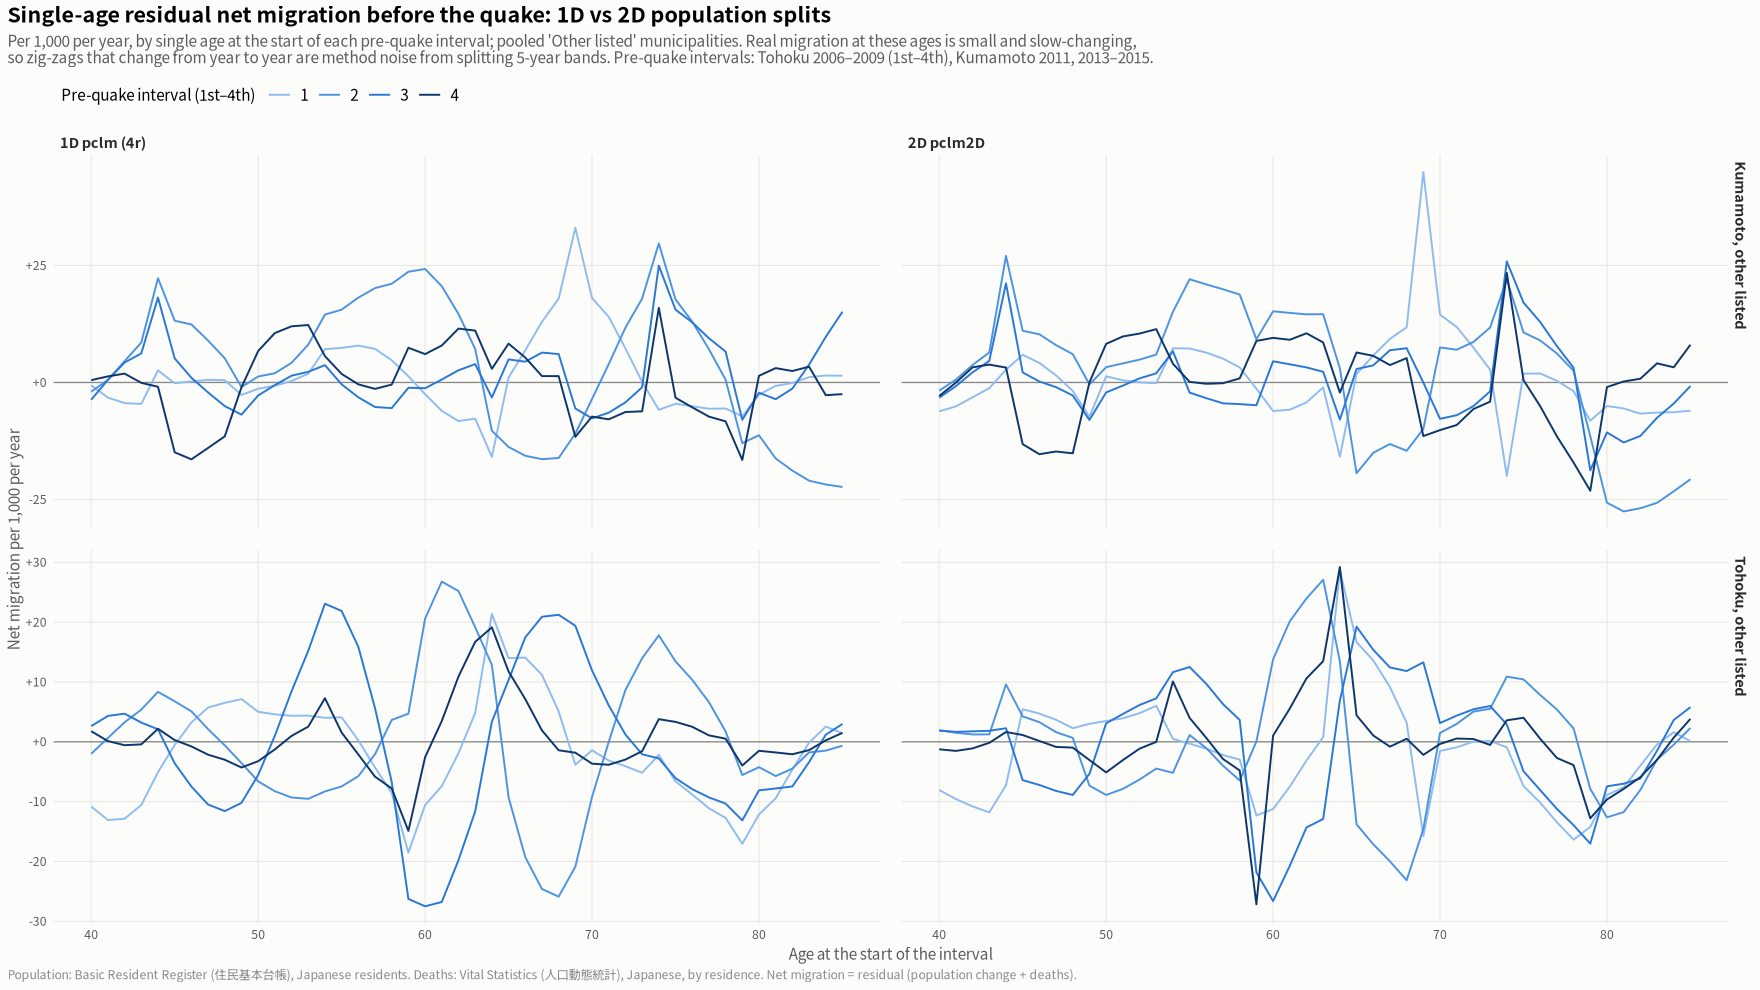

In [8]:
sa <- bind_rows(res_1d |> mutate(method = "1D pclm (4r)"), res_2d |> mutate(method = "2D pclm2D")) |>
  filter(grepl("^Other", group), start < q, span == 1, age %in% 40:85) |>
  group_by(method, event, start, age) |>
  summarise(rate = 1000 * sum(NM) / sum(P0), .groups = "drop") |>
  mutate(event = factor(ifelse(event == "tohoku", "Tohoku, other listed", "Kumamoto, other listed")),
         k = factor(match(start, sort(unique(start)))))
sa <- sa |> group_by(event) |> mutate(k = factor(dense_rank(as.integer(as.character(start))))) |> ungroup()
p1 <- ggplot(sa, aes(age, rate, colour = k, group = k)) +
  geom_hline(yintercept = 0, colour = ink3, linewidth = 0.4) +
  geom_line(linewidth = 0.6) +
  facet_grid(event ~ method, scales = "free_y") +
  scale_colour_manual(values = c("#8fbcef", "#4d94e0", "#2a78d6", "#0d366b"),
                      name = "Pre-quake interval (1st–4th)") +
  scale_y_continuous(labels = function(v) sprintf("%+g", v)) +
  labs(title = "Single-age residual net migration before the quake: 1D vs 2D population splits",
       subtitle = paste0("Per 1,000 per year, by single age at the start of each pre-quake interval; pooled 'Other listed' municipalities. ",
                         "Real migration at these ages is small and slow-changing,\nso zig-zags that change from year to year are method noise from splitting 5-year bands. Pre-quake intervals: Tohoku 2006–2009 (1st–4th), Kumamoto 2011, 2013–2015."),
       x = "Age at the start of the interval", y = "Net migration per 1,000 per year", caption = src_note) +
  base_theme() + theme(panel.grid.major.x = element_line(colour = grid_col, linewidth = 0.3))
show_save(p1, "01_single_age_residual_1d_vs_2d", width = 16, height = 8)

## Figure 2: method noise by age band, 1D vs 2D

The yardstick from 4r: for each group and 5-year age band, the SD across the single pre-quake (full-year) intervals of the net rate. Lower is better.

event,group,method,all_ages,ages_0_14,ages_20_39,ages_55_79
<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
kumamoto,High damage (全壊率 ≥ 1),1D pclm (4r),13.3,6.3,10.9,15.2
kumamoto,High damage (全壊率 ≥ 1),2D pclm2D,11.9,6.0,10.5,12.1
kumamoto,Other listed (Kumamoto),1D pclm (4r),7.7,3.6,8.2,8.2
kumamoto,Other listed (Kumamoto),2D pclm2D,7.4,3.1,7.5,7.9
kumamoto,熊本市,1D pclm (4r),7.5,5.0,6.0,6.3
kumamoto,熊本市,2D pclm2D,6.7,4.0,5.7,5.4
tohoku,Other listed (Tohoku),1D pclm (4r),4.2,1.9,3.1,8.0
tohoku,Other listed (Tohoku),2D pclm2D,4.6,1.8,3.6,7.5
tohoku,岩手・宮城 全壊率 ≥ 1,1D pclm (4r),5.3,3.7,4.1,7.5


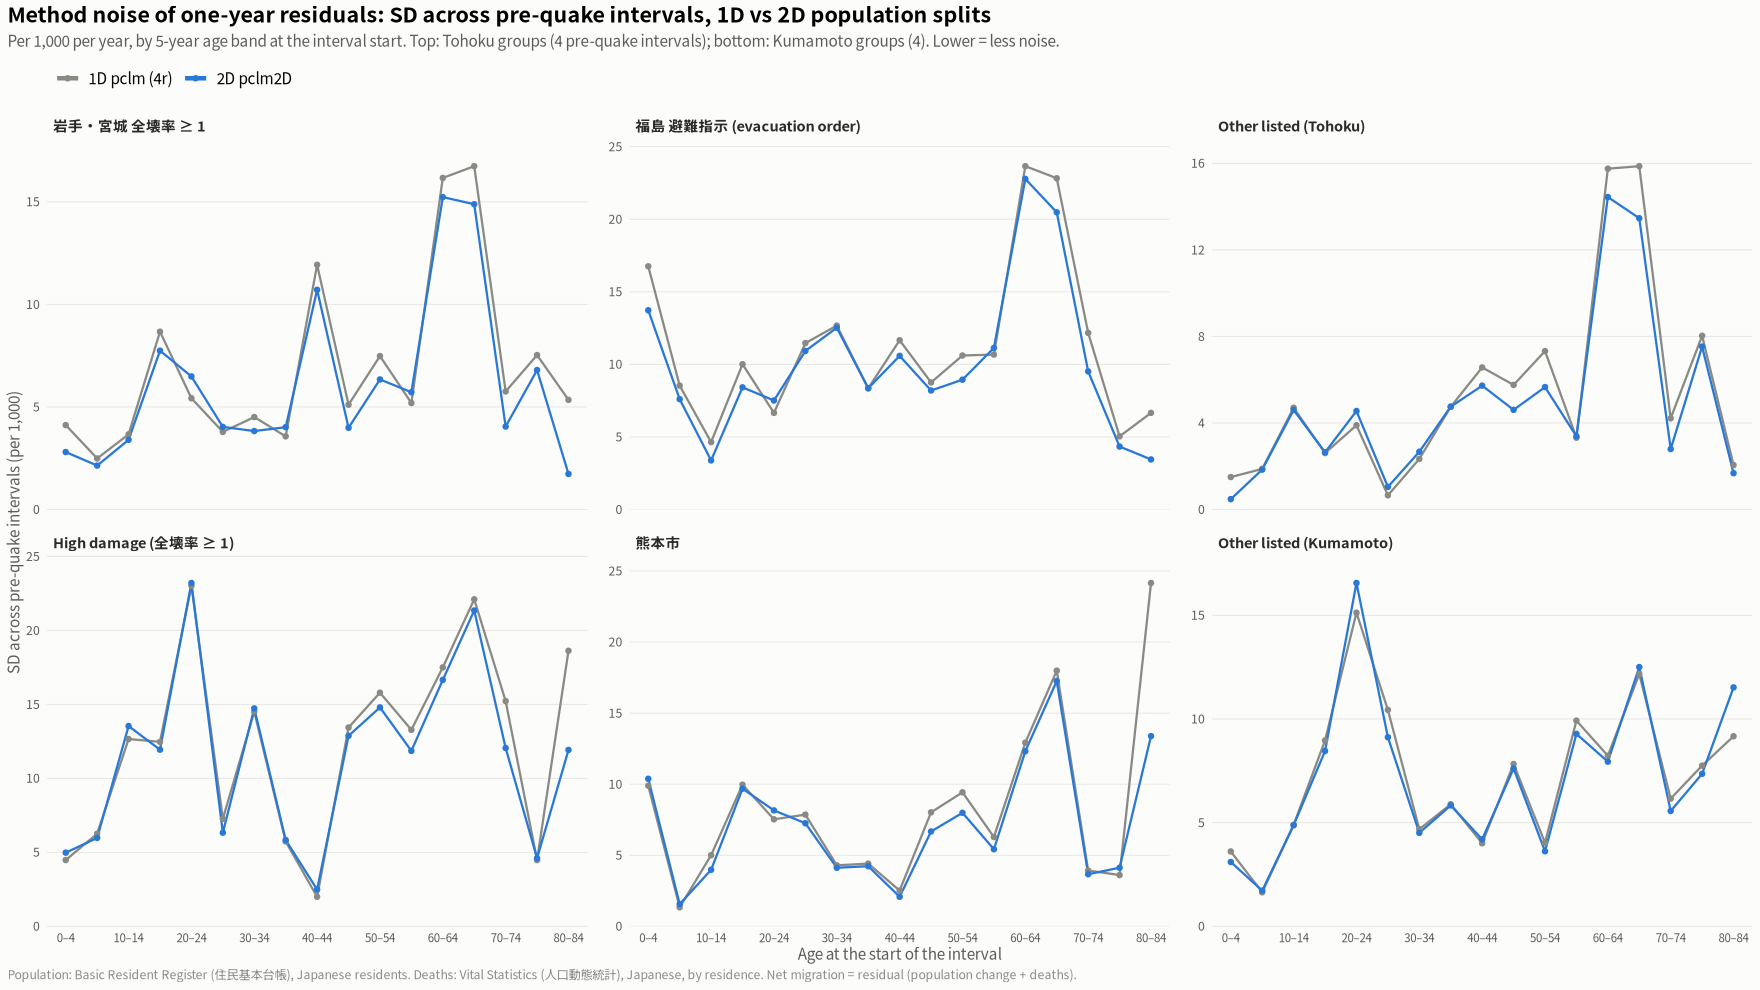

In [9]:
noise_of <- function(res, label) {
  res |> filter(!is.na(band), start < q, span == 1) |>
    group_by(event, group, band, start) |>
    summarise(rate = 1000 * sum(NM) / sum(P0), .groups = "drop") |>
    group_by(event, group, band) |>
    summarise(pre_mean = mean(rate), pre_sd = sd(rate), .groups = "drop") |>
    mutate(method = label)
}
nz <- bind_rows(noise_of(res_1d, "1D pclm (4r)"), noise_of(res_2d, "2D pclm2D"))

# Table: median noise SD over age bands, by group (and for the target ages)
nz |> group_by(event, group, method) |>
  summarise(all_ages = round(median(pre_sd), 1),
            ages_0_14 = round(median(pre_sd[band %in% bands5[1:3]]), 1),
            ages_20_39 = round(median(pre_sd[band %in% bands5[5:8]]), 1),
            ages_55_79 = round(median(pre_sd[band %in% bands5[12:16]]), 1), .groups = "drop") |>
  as.data.frame()

p2 <- ggplot(nz |> mutate(group = factor(group, levels = unlist(group_levels))),
             aes(band, pre_sd, colour = method, group = method)) +
  geom_line(linewidth = 0.7) + geom_point(size = 1.4) +
  facet_wrap(~group, nrow = 2, scales = "free_y") +
  scale_colour_manual(values = c("1D pclm (4r)" = "#8a8a85", "2D pclm2D" = "#2a78d6"), name = NULL) +
  scale_x_discrete(labels = function(b) ifelse(seq_along(b) %% 2 == 1, b, "")) +
  scale_y_continuous(limits = c(0, NA), expand = expansion(mult = c(0, 0.08))) +
  labs(title = "Method noise of one-year residuals: SD across pre-quake intervals, 1D vs 2D population splits",
       subtitle = "Per 1,000 per year, by 5-year age band at the interval start. Top: Tohoku groups (4 pre-quake intervals); bottom: Kumamoto groups (4). Lower = less noise.",
       x = "Age at the start of the interval", y = "SD across pre-quake intervals (per 1,000)", caption = src_note) +
  base_theme() + theme(axis.text.x = element_text(size = 7.5)) +
  guides(colour = guide_legend(override.aes = list(linewidth = 1.4)))
show_save(p2, "02_noise_1d_vs_2d", width = 16, height = 9)

## Figure 3: validation against reported migration, 1D vs 2D (Kumamoto 2014–2020)

The reported side is the same in both, built from the 1D fits of in- and out-movers (Japanese movers, same Lexis split). The table and figure show the gap (residual − reported) for municipality × cohort × year cells:
- its correlation and SD by cohort bin;
- the same by municipality size;
- whole municipalities with all ages summed.

In [10]:
M1 <- fits1d |> filter(series %in% c("in", "out")) |>
  select(code, year, series, age, M = fit) |>
  group_by(code, year, series) |> arrange(age, .by_group = TRUE) |>
  mutate(Mc = 0.5 * (M + lead(M, default = 0))) |> ungroup() |>
  select(-M) |> pivot_wider(names_from = series, values_from = Mc)

In [11]:
val_of <- function(res, label) {
  res |> filter(event == "kumamoto", start %in% 2014:2020, !is.na(cohort)) |>
    inner_join(M1 |> rename(start = year), by = c("code", "start", "age")) |>
    group_by(code, short, group, cohort, start) |>
    summarise(P0 = sum(P0), NM = sum(NM), rep = sum(`in`) - sum(out), .groups = "drop") |>
    mutate(residual = 1000 * NM / P0, reported = 1000 * rep / P0, gap = residual - reported, method = label)
}
val <- bind_rows(val_of(res_1d, "1D pclm (4r)"), val_of(res_2d, "2D pclm2D"))
munipop <- pop5 |> filter(age_band == "total", year == 2016) |> select(code, pop2016 = n)
val <- val |> left_join(munipop, by = "code") |>
  mutate(size = cut(pop2016, c(0, 5000, 10000, 20000, 50000, 1e7),
                    labels = c("< 5k", "5–10k", "10–20k", "20–50k", "≥ 50k")))

cat("By cohort bin:\n")
val |> group_by(cohort, method) |>
  summarise(sd_gap = round(sd(gap), 1), corr = round(cor(residual, reported), 2), .groups = "drop") |>
  pivot_wider(names_from = method, values_from = c(sd_gap, corr)) |> as.data.frame()
cat("By municipality size:\n")
val |> group_by(size, method) |>
  summarise(sd_gap = round(sd(gap), 1), corr = round(cor(residual, reported), 2), .groups = "drop") |>
  pivot_wider(names_from = method, values_from = c(sd_gap, corr)) |> as.data.frame()
cat("Whole municipality-years (all cohorts summed) and all cells:\n")
val |> group_by(method) |>
  summarise(cells_corr = round(cor(residual, reported), 3), cells_sd_gap = round(sd(gap), 1), .groups = "drop") |>
  left_join(val |> group_by(method, code, start) |>
              summarise(r = 1000 * sum(NM) / sum(P0), p = 1000 * sum(rep) / sum(P0), .groups = "drop") |>
              group_by(method) |> summarise(muni_corr = round(cor(r, p), 3), muni_sd_gap = round(sd(r - p), 2)),
            by = "method") |> as.data.frame()

By cohort bin:


cohort,sd_gap_1D pclm (4r),sd_gap_2D pclm2D,corr_1D pclm (4r),corr_2D pclm2D
<fct>,<dbl>,<dbl>,<dbl>,<dbl>
0–4,40.1,37.7,0.35,0.38
5–9,24.9,23.1,0.53,0.55
10–14,33.5,30.7,0.45,0.50
15–19,36.8,34.4,0.75,0.78
20–24,39.7,38.5,0.72,0.72
25–29,32.6,31.2,0.67,0.68
30–34,28.7,27.4,0.60,0.61
35–39,28.1,26.2,0.50,0.52
40–49,14.6,13.4,0.58,0.60


By municipality size:


size,sd_gap_1D pclm (4r),sd_gap_2D pclm2D,corr_1D pclm (4r),corr_2D pclm2D
<fct>,<dbl>,<dbl>,<dbl>,<dbl>
< 5k,50.8,48.7,0.60,0.62
5–10k,27.7,26.4,0.72,0.74
10–20k,21.4,19.4,0.81,0.83
20–50k,12.5,11.1,0.87,0.89
≥ 50k,8.5,7.7,0.92,0.93


Whole municipality-years (all cohorts summed) and all cells:


method,cells_corr,cells_sd_gap,muni_corr,muni_sd_gap
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
1D pclm (4r),0.717,28.2,0.973,1.72
2D pclm2D,0.734,26.6,0.967,1.97


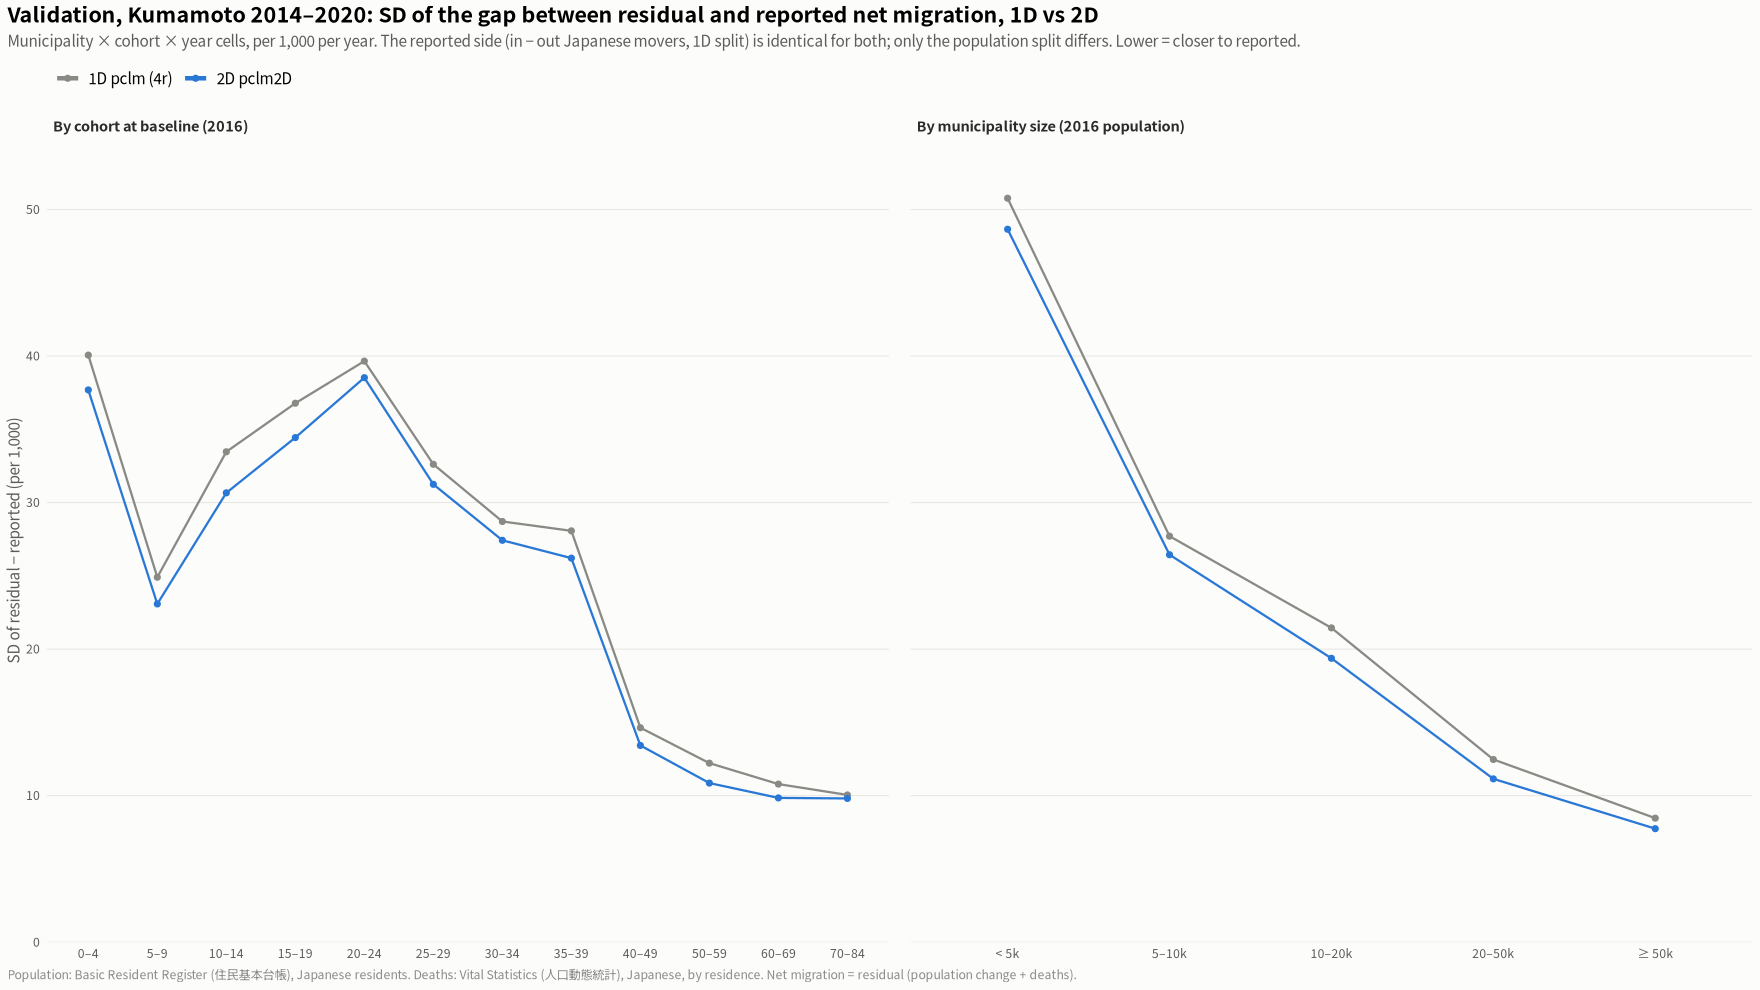

In [12]:
vs <- bind_rows(
  val |> group_by(method, x = cohort) |> summarise(sd_gap = sd(gap), .groups = "drop") |> mutate(panel = "By cohort at baseline (2016)"),
  val |> group_by(method, x = size) |> summarise(sd_gap = sd(gap), .groups = "drop") |> mutate(panel = "By municipality size (2016 population)")) |>
  mutate(x = factor(x, levels = c(cohort_bins, "< 5k", "5–10k", "10–20k", "20–50k", "≥ 50k")))
p3 <- ggplot(vs, aes(x, sd_gap, colour = method, group = method)) +
  geom_line(linewidth = 0.7) + geom_point(size = 1.6) +
  facet_wrap(~panel, scales = "free_x") +
  scale_colour_manual(values = c("1D pclm (4r)" = "#8a8a85", "2D pclm2D" = "#2a78d6"), name = NULL) +
  scale_y_continuous(limits = c(0, NA), expand = expansion(mult = c(0, 0.08))) +
  labs(title = "Validation, Kumamoto 2014–2020: SD of the gap between residual and reported net migration, 1D vs 2D",
       subtitle = paste0("Municipality × cohort × year cells, per 1,000 per year. The reported side (in − out Japanese movers, 1D split) is identical for both; ",
                         "only the population split differs. Lower = closer to reported."),
       x = NULL, y = "SD of residual − reported (per 1,000)", caption = src_note) +
  base_theme() +
  guides(colour = guide_legend(override.aes = list(linewidth = 1.4)))
show_save(p3, "03_validation_1d_vs_2d", width = 16, height = 6.5)

## Figures 4–7: the 4r group figures with 2D population splits

The same figures as 4r figures 2–5, recomputed with the 2D splits. The noise bands and the ⚠ flags for the 1944–50 births are drawn as in 4r, from the 2D residuals.

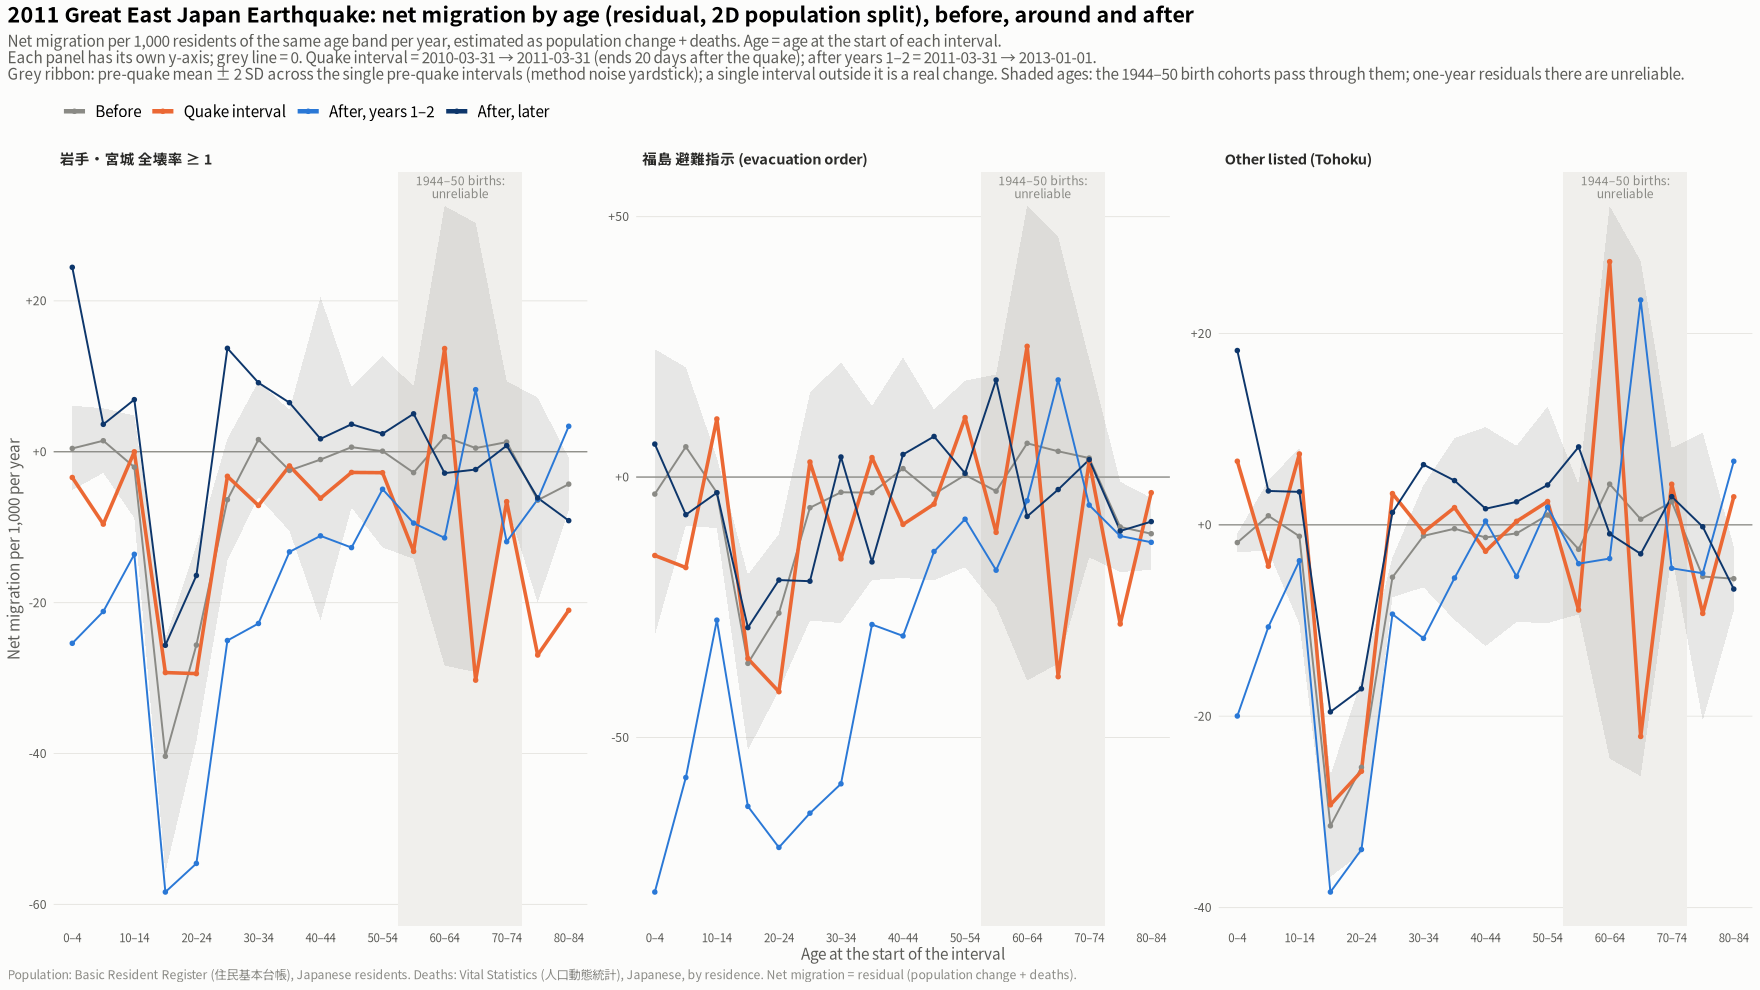

In [13]:
res1 <- res_2d |> filter(a0 >= 0)
profile <- res1 |> filter(!is.na(band)) |>
  group_by(event, group, period, band) |>
  summarise(rate = 1000 * sum(NM) / sum(P0 * span), .groups = "drop")
noise <- noise_of(res_2d, "2D")
cliff_births <- 1944:1950
cliff_bands <- lapply(events, function(ev) {
  st <- head(ev$counts, -1)
  ages <- range(outer(st, cliff_births, function(t, b) t - b - 1))
  bands5[seq(ages[1] %/% 5 + 1, min(ages[2] %/% 5 + 1, length(bands5)))]
})


plot_profile <- function(e) {
  dd <- profile |> filter(event == e) |> mutate(group = factor(group, levels = group_levels[[e]]))
  nz <- noise |> filter(event == e) |> mutate(group = factor(group, levels = group_levels[[e]]))
  cb <- match(cliff_bands[[e]], bands5)
  ggplot(dd, aes(band, rate, colour = period, group = period)) +
    annotate("rect", xmin = min(cb) - 0.5, xmax = max(cb) + 0.5, ymin = -Inf, ymax = Inf, fill = "#f0efec") +
    annotate("text", x = mean(cb), y = Inf, label = "1944–50 births:\nunreliable", vjust = 1.2,
             size = 2.8, colour = ink3, family = jp_font, lineheight = 0.9) +
    geom_ribbon(data = nz, aes(x = band, ymin = pre_mean - 2 * pre_sd, ymax = pre_mean + 2 * pre_sd, group = 1),
                inherit.aes = FALSE, fill = "#8a8a85", alpha = 0.18) +
    geom_hline(yintercept = 0, colour = ink3, linewidth = 0.4) +
    geom_line(aes(linewidth = period == periods[2])) +
    geom_point(size = 1.1) +
    facet_wrap(~group, nrow = 1, scales = "free_y") +
    scale_colour_manual(values = period_cols, name = NULL) +
    scale_linewidth_manual(values = c(`FALSE` = 0.6, `TRUE` = 1.1), guide = "none") +
    scale_x_discrete(labels = function(b) ifelse(seq_along(b) %% 2 == 1, b, "")) +
    scale_y_continuous(labels = function(v) sprintf("%+g", v)) +
    labs(title = paste0(events[[e]]$title, ": net migration by age (residual), before, around and after"),
         subtitle = paste0("Net migration per 1,000 residents of the same age band per year, estimated as population change + deaths. ",
                           "Age = age at the start of each interval.\nEach panel has its own y-axis; grey line = 0. ",
                           if (e == "tohoku") "Quake interval = 2010-03-31 → 2011-03-31 (ends 20 days after the quake); after years 1–2 = 2011-03-31 → 2013-01-01."
                           else "Quake interval = calendar 2016; after years 1–2 = 2017–2018; later = 2019–2020.",
                           "\nGrey ribbon: pre-quake mean ± 2 SD across the single pre-quake intervals (method noise yardstick); a single interval outside it is a real change. ",
                           "Shaded ages: the 1944–50 birth cohorts pass through them; one-year residuals there are unreliable."),
         x = "Age at the start of the interval", y = "Net migration per 1,000 per year", caption = src_note) +
    base_theme() +
    theme(axis.text.x = element_text(size = 7.5)) +
    guides(colour = guide_legend(override.aes = list(linewidth = 1.4)))
}

show_save(plot_profile("tohoku") + labs(title = "2011 Great East Japan Earthquake: net migration by age (residual, 2D population split), before, around and after"),
          "04_tohoku_age_profile_2d", width = 16, height = 6.5)

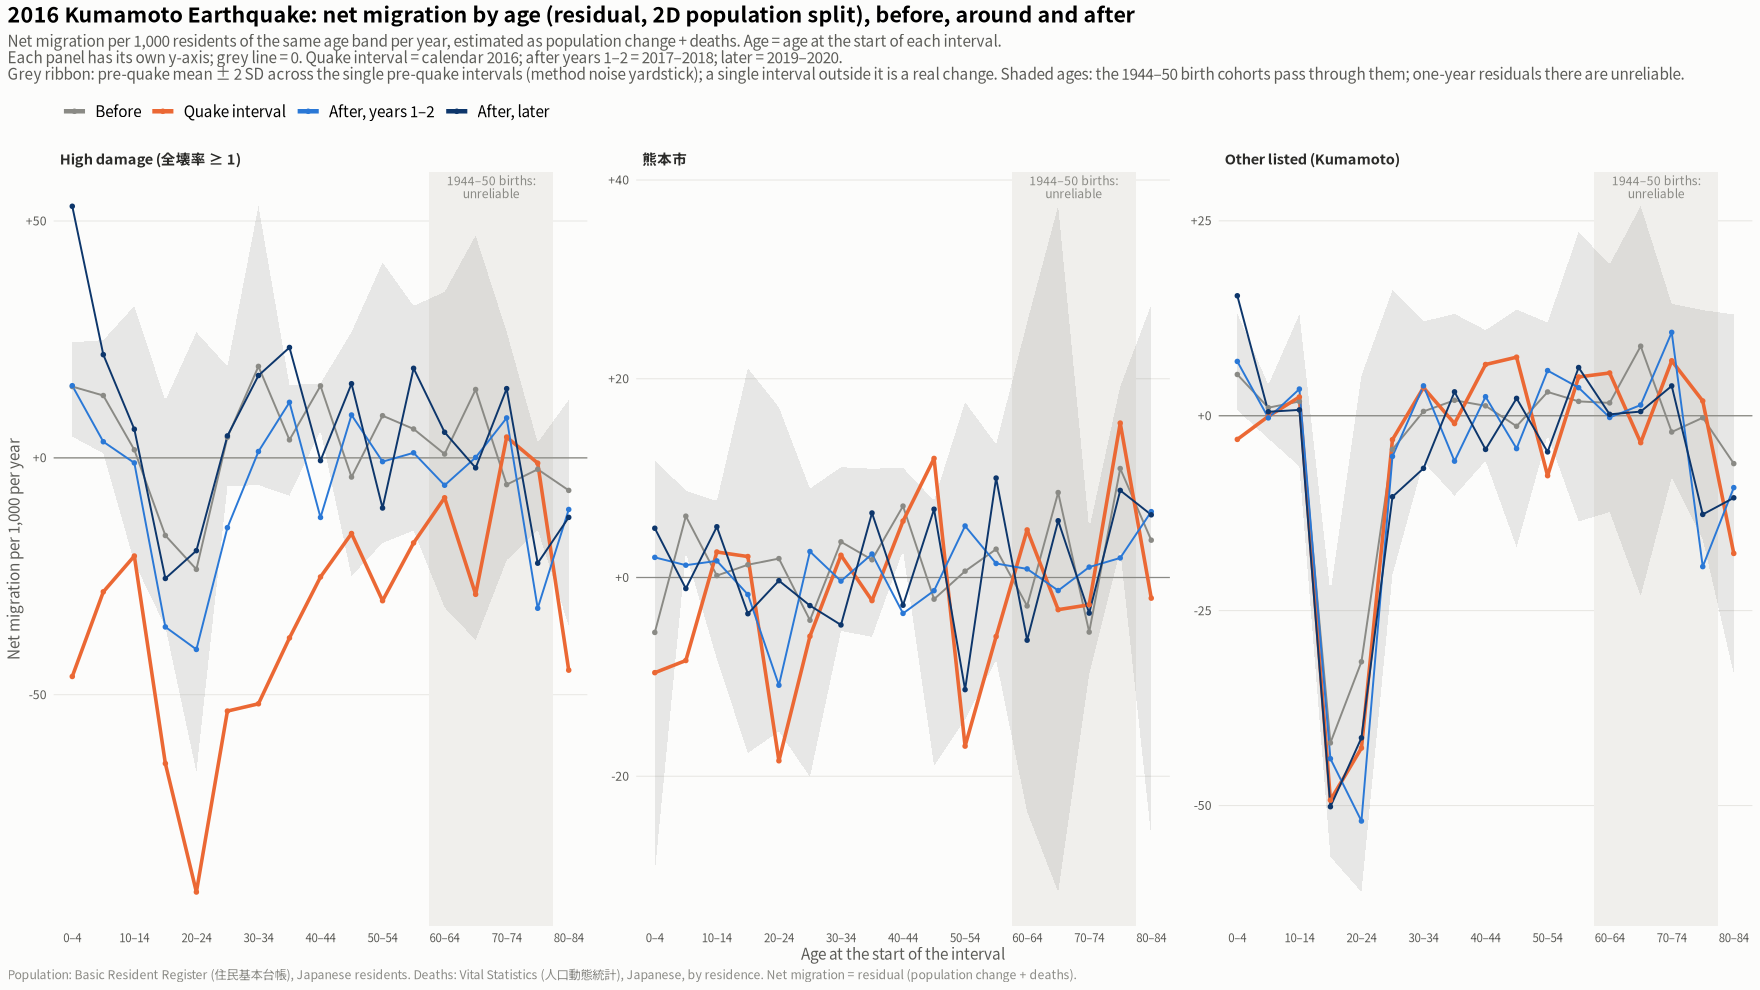

In [14]:
show_save(plot_profile("kumamoto") + labs(title = "2016 Kumamoto Earthquake: net migration by age (residual, 2D population split), before, around and after"),
          "05_kumamoto_age_profile_2d", width = 16, height = 6.5)

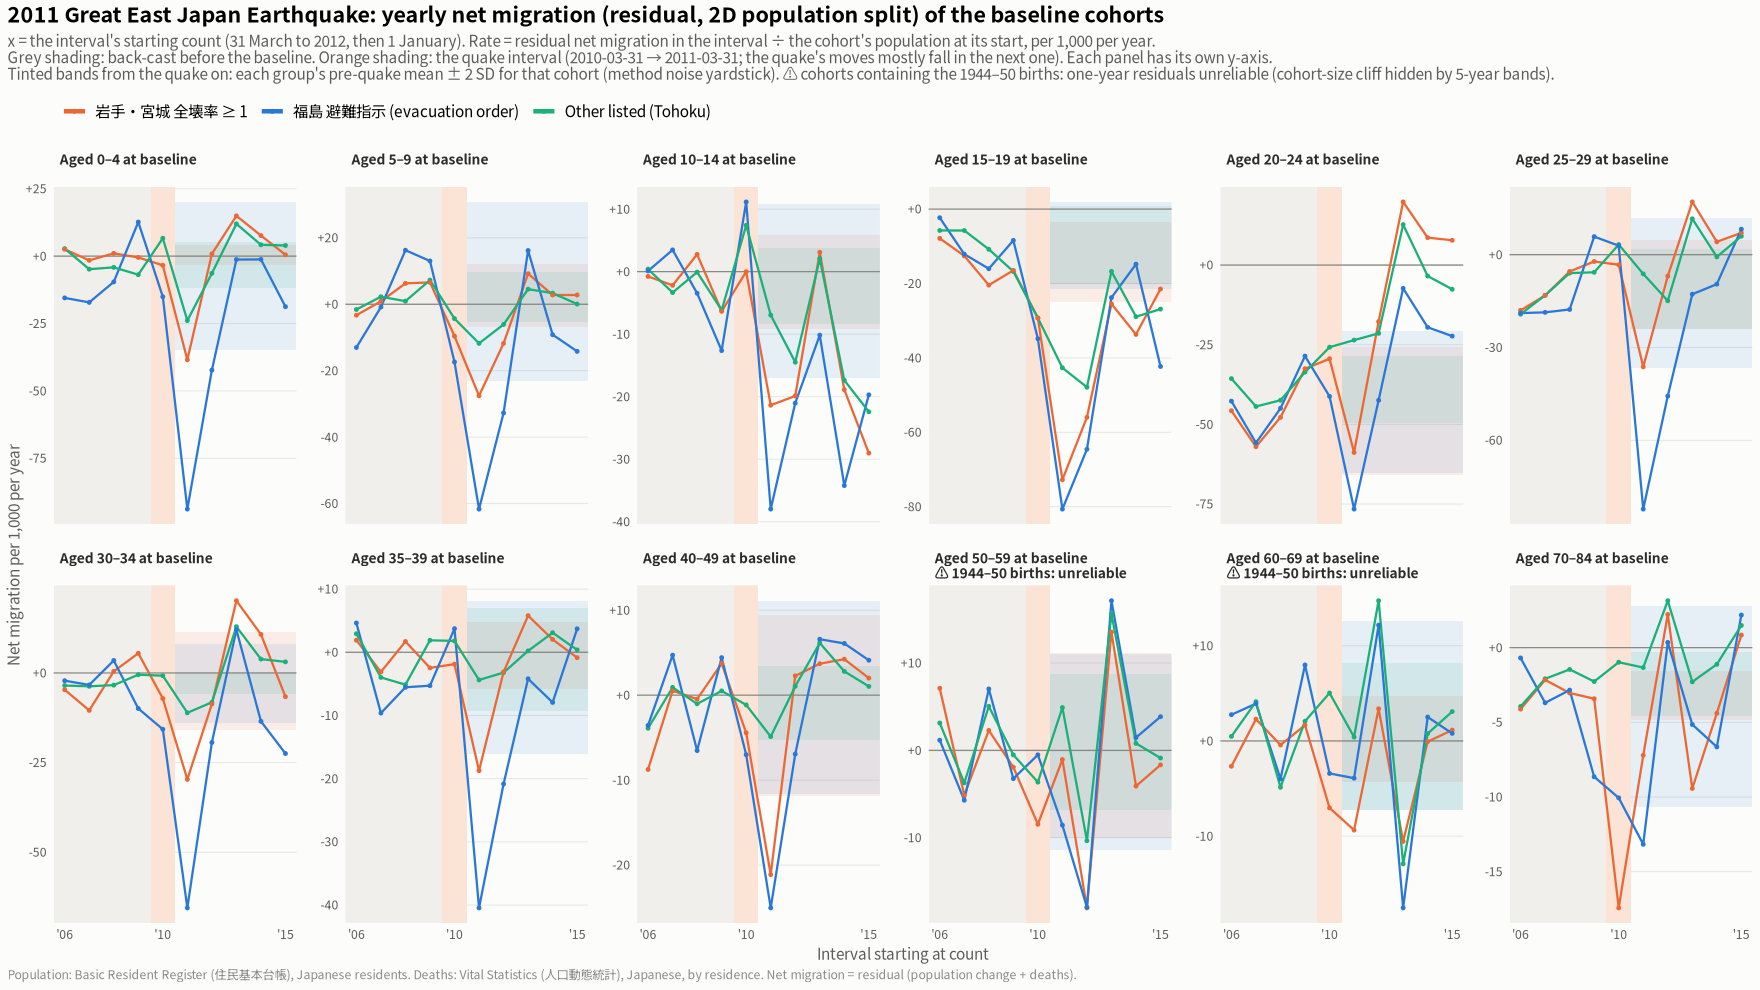

In [15]:
cr_group <- res1 |> filter(!is.na(cohort)) |>
  group_by(event, group, cohort, start) |>
  summarise(rate = 1000 * sum(NM) / sum(P0 * span), .groups = "drop")
plot_cohorts <- function(e) {
  ev <- events[[e]]
  # cohort bins containing the 1944-50 births are flagged in the panel title
  born <- function(lab) { r <- as.integer(strsplit(as.character(lab), "–")[[1]]); ev$base - rev(r) - 1 }
  flag <- sapply(cohort_bins, function(b) any(born(b)[1]:born(b)[2] %in% cliff_births))
  labs_c <- paste0("Aged ", cohort_bins, " at baseline", ifelse(flag, "\n⚠ 1944–50 births: unreliable", "\n"))
  dd <- cr_group |> filter(event == e) |>
    mutate(group = factor(group, levels = group_levels[[e]]),
           cohort_lab = factor(labs_c[match(cohort, cohort_bins)], levels = labs_c))
  # Noise band: mean +- 2 SD of the cohort's own back-cast (pre-quake, full-year) intervals
  nb <- dd |> filter(start < ev$quake_start, !(start == 2012)) |>
    group_by(group, cohort_lab) |>
    summarise(lo = mean(rate) - 2 * sd(rate), hi = mean(rate) + 2 * sd(rate), .groups = "drop")
  ggplot(dd, aes(start, rate, colour = group)) +
    geom_rect(data = nb, aes(xmin = ev$quake_start - 0.5, xmax = Inf, ymin = lo, ymax = hi, fill = group),
              inherit.aes = FALSE, alpha = 0.10) +
    scale_fill_manual(values = group_cols[group_levels[[e]]], guide = "none") +
    annotate("rect", xmin = -Inf, xmax = ev$base - 0.5, ymin = -Inf, ymax = Inf, fill = "#f0efec") +
    annotate("rect", xmin = ev$quake_start - 0.5, xmax = ev$quake_start + 0.5, ymin = -Inf, ymax = Inf,
             fill = "#fbe3d6") +
    geom_hline(yintercept = 0, colour = ink3, linewidth = 0.4) +
    geom_line(linewidth = 0.7) +
    geom_point(size = 0.9) +
    facet_wrap(~cohort_lab, nrow = 2, scales = "free_y") +
    scale_colour_manual(values = group_cols[group_levels[[e]]], name = NULL) +
    scale_x_continuous(breaks = c(min(ev$counts), ev$base, max(ev$counts) - 1),
                       labels = function(v) paste0("'", substr(v, 3, 4))) +
    scale_y_continuous(labels = function(v) sprintf("%+g", v)) +
    labs(title = paste0(ev$title, ": yearly net migration (residual) of the cohorts present at the baseline count"),
         subtitle = paste0("x = the interval's starting count (", if (e == "tohoku") "31 March to 2012, then 1 January" else "1 January from 2013",
                           "). Rate = residual net migration in the interval ÷ the cohort's population at its start, per 1,000 per year.\n",
                           "Grey shading: back-cast before the baseline. Orange shading: the quake interval",
                           if (e == "tohoku") " (2010-03-31 → 2011-03-31; the quake's moves mostly fall in the next one)." else " (calendar 2016).",
                           " Each panel has its own y-axis.\nTinted bands from the quake on: each group's pre-quake mean ± 2 SD for that cohort (method noise yardstick). ",
                           "⚠ cohorts containing the 1944–50 births: one-year residuals unreliable (cohort-size cliff hidden by 5-year bands)."),
         x = "Interval starting at count", y = "Net migration per 1,000 per year", caption = src_note) +
    base_theme() +
    theme(strip.text = element_text(size = 9)) +
    guides(colour = guide_legend(override.aes = list(linewidth = 1.4)))
}

show_save(plot_cohorts("tohoku") + labs(title = "2011 Great East Japan Earthquake: yearly net migration (residual, 2D population split) of the baseline cohorts"),
          "06_tohoku_cohort_rates_2d", width = 18, height = 9)

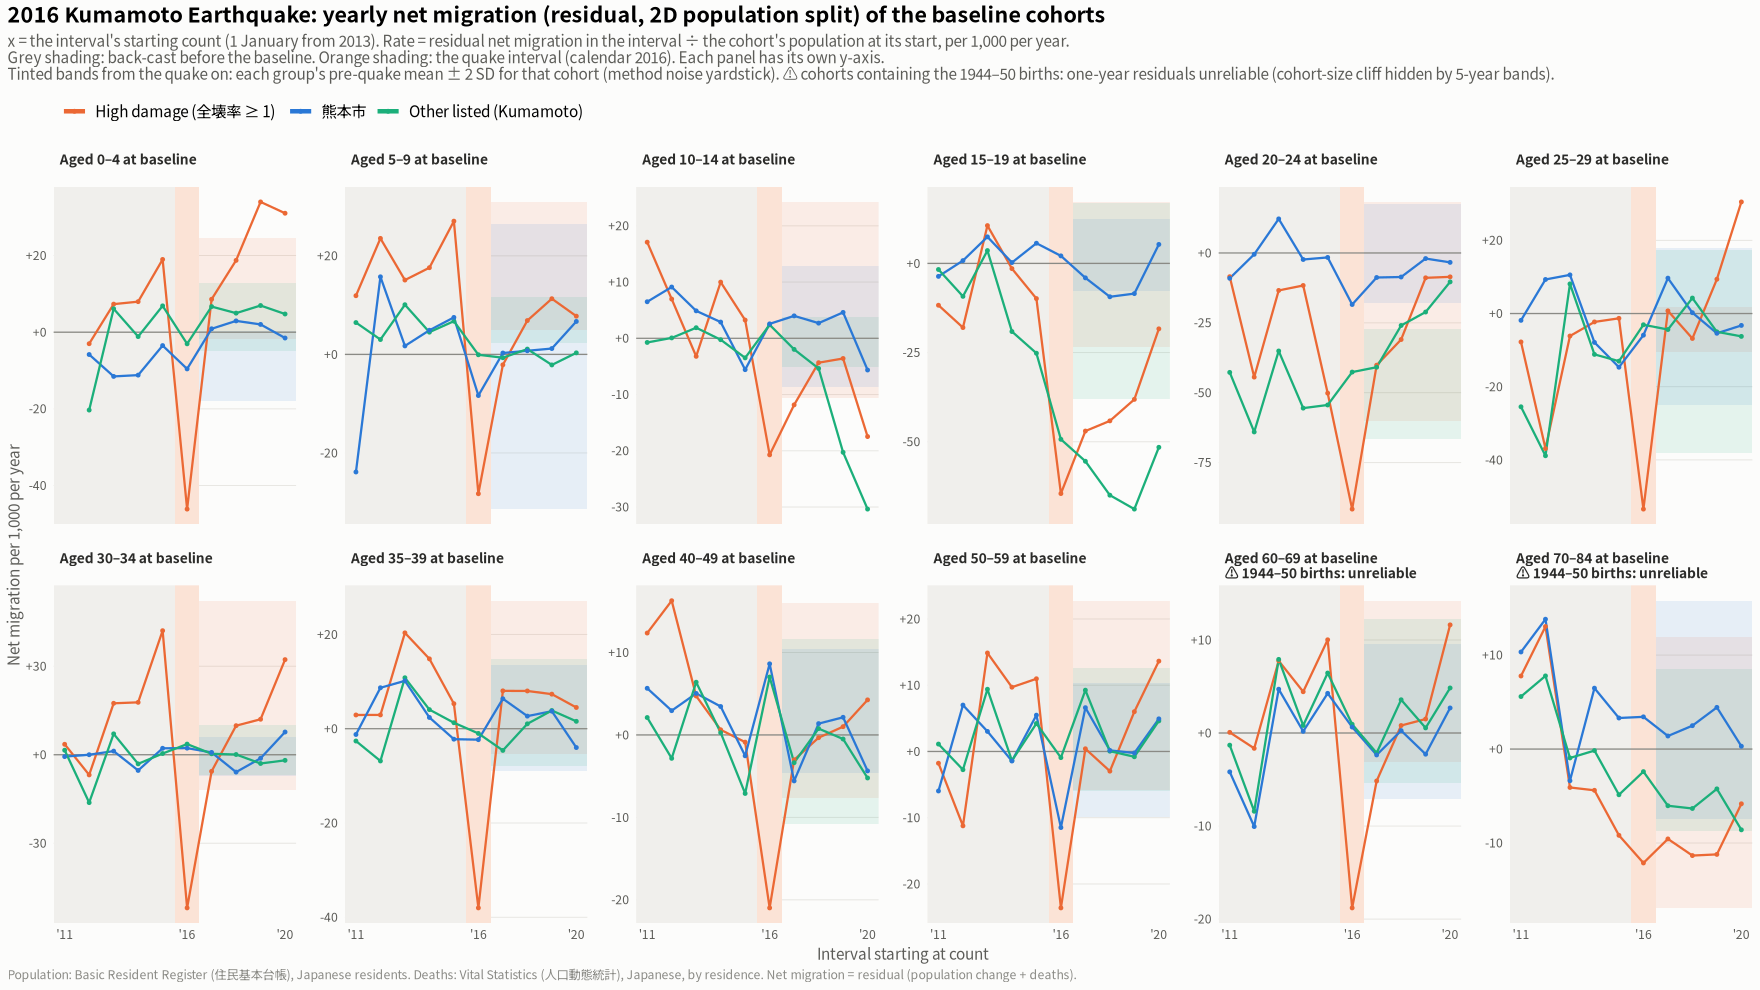

In [16]:
show_save(plot_cohorts("kumamoto") + labs(title = "2016 Kumamoto Earthquake: yearly net migration (residual, 2D population split) of the baseline cohorts"),
          "07_kumamoto_cohort_rates_2d", width = 18, height = 9)

## Figure 8: Kumamoto age profile comparable to 3r figure 3

3r figure 3 (`res/3r_03_kumamoto_inout_5yr.png`) shows reported in-, out- and net migration by published 5-year age band for four periods: before (2014–15), the quake year (2016), after (2017–19) and later (2020–25). Groups are the high-damage municipalities, 熊本市 and the other listed ones. The residual gives only **net** migration, so this figure puts the two net estimates one above the other, with the same groups, periods, age bands and a shared y-axis:

- **Top row:** reported net from 3r: (in − out) Japanese movers between municipalities ÷ 1 January population of the same band, per 1,000 per year.
- **Bottom row:** residual net from the 2D population split: (population change + deaths) ÷ 1 January population of the same band, per 1,000 per year.

**Window:** to cover 2020–25, the Kumamoto window is extended here to counts 2011-03-31 … 2026-01-01 and deaths 2011–2025. The 2D population fit is redone over that window and cached separately; deaths are 1D, as everywhere else. Each interval from 2014 is one calendar year, so the periods match 3r exactly.

**No national shape here:** the national single-year population used as offset elsewhere in 4r/5r is only available to 1 October 2020. The extended fit therefore uses plain `pclm2D` (no offset), with the same BIC-chosen smoothing and band rescaling. Without the offset, cohort-size cliffs are smoothed, so the one-year residual is noisier at the ages of the 1944–50 births, about 65–79 in this window.

**Expected differences**
- **Age:** reported movers are by age at the move, the residual by age on 1 January, about half a year younger. Peaks can shift by part of a band.
- **What the residual includes:** moves to and from abroad and register corrections, which the reported (between-municipality) figures leave out.
- **Noise:** the residual carries the band-edge noise described above, worst for the 1944–50 births at ages 65–79.

In [17]:
kum <- study |> filter(event == "kumamoto")
cache_k <- file.path(root, "output/5r_pclm_kumamoto_2011_2026.qs2")
if (file.exists(cache_k)) {
  fk <- qs_read(cache_k)
} else {
  pop_k <- qs_read(file.path(root, "dt/jumin_age_sex_5yr_long.qs2")) |>
    filter(code %in% kum$code, basis == "japanese", sex == "計", year %in% 2011:2026) |>
    mutate(age_band = as.character(age_band), ref = substr(ref_date, 6, 10)) |>
    select(code, year, ref, age_band, n = pop)
  dth_k <- qs_read(file.path(root, "dt/deaths_age_sex_5yr_long.qs2")) |>
    filter(code %in% kum$code, sex == "計", year %in% 2011:2025) |>
    mutate(age_band = as.character(age_band)) |> select(code, year, age_band, n)
  t0 <- Sys.time()
  fk <- list(
    pop = pop_k |> group_by(code) |>
      group_modify(function(g, k) { r <- fit2d_muni(g, use_offset = FALSE); if (is.null(r)) tibble() else r }) |> ungroup(),
    deaths = dth_k |> group_by(code, year) |>
      group_modify(function(g, k) ungroup_bands(g$age_band, g$n)) |> ungroup())
  message("Kumamoto 2011-2026 fits in ", round(as.numeric(difftime(Sys.time(), t0, units = "mins")), 1), " min")
  qs_save(fk, cache_k)
}
cat("2D population fits:", n_distinct(fk$pop$code), "of", nrow(kum), " | death fits:", n_distinct(paste(fk$deaths$code, fk$deaths$year)), "\n")

# Deaths per interval (as in 4r): 2011 = Apr 2011-Mar 2012, 2012 = 0.75-year interval, then calendar years
Dk <- fk$deaths |> select(code, year, age, D = fit) |>
  pivot_wider(names_from = year, values_from = D, names_prefix = "D")
dk <- function(y) Dk[[paste0("D", y)]]
DI_k <- bind_rows(lapply(2011:2025, function(s) {
  d <- if (s == 2011) 0.75 * dk(2011) + 0.25 * dk(2012) else if (s == 2012) 0.75 * dk(2012) else dk(s)
  tibble(code = Dk$code, age = Dk$age, start = s, Dint = d)
}))

# Residual with the same function as above, on the extended Kumamoto window
P_k <- fk$pop |> select(code, count = year, age, P = fit)
events_save <- events; DI_save <- DI
events$kumamoto$counts <- 2011:2026
DI <- DI_k
res_k <- compute_res(P_k) |> filter(event == "kumamoto")
events <- events_save; DI <- DI_save

periods3 <- c("Before (2014–15)", "Quake year (2016)", "After (2017–19)", "Later (2020–25)")
period_of3 <- function(y) factor(case_when(y <= 2015 ~ periods3[1], y == 2016 ~ periods3[2],
                                           y <= 2019 ~ periods3[3], TRUE ~ periods3[4]), levels = periods3)
bands3 <- c(paste0(seq(0, 75, 5), "_", seq(4, 79, 5)), "80+")
band3_of_age <- function(a) ifelse(a >= 80, "80+", paste0(a %/% 5 * 5, "_", a %/% 5 * 5 + 4))

resid3 <- res_k |> filter(start %in% 2014:2025) |>
  mutate(band = band3_of_age(age), period = period_of3(start)) |>
  group_by(group, period, band) |>
  summarise(rate = 1000 * sum(NM) / sum(P0), .groups = "drop") |>
  mutate(source = "Residual net (5r: 2D population split + deaths)")

# Reported net, exactly as in 3r figure 3 (published bands, Japanese movers / population)
to80b <- function(b) ifelse(b %in% c("80_84", "85_89", "90+", "90_94", "95_99", "100+", "80+"), "80+", b)
p3r <- qs_read(file.path(root, "dt/jumin_age_sex_5yr_long.qs2")) |>
  filter(code %in% kum$code, basis == "japanese", sex == "計", year %in% 2014:2025) |>
  mutate(age_band = as.character(age_band)) |>
  filter(age_band != "total", !(age_band == "80+" & year >= 2015)) |>
  mutate(band = to80b(age_band)) |>
  group_by(code, year, band) |> summarise(pop = sum(pop), .groups = "drop")
m3r <- qs_read(file.path(root, "dt/idou_age_sex_5yr_long.qs2")) |>
  filter(code %in% kum$code, level == "municipality", mover == "japanese", sex == "計",
         year %in% 2014:2025, !age_band %in% c("total", "origin_unknown")) |>
  mutate(band = to80b(as.character(age_band))) |>
  group_by(code, year, band, direction) |> summarise(n = sum(n), .groups = "drop") |>
  pivot_wider(names_from = direction, values_from = n)
rep3 <- p3r |> inner_join(m3r, by = c("code", "year", "band")) |>
  left_join(kum |> select(code, group), by = "code") |>
  mutate(period = period_of3(year)) |>
  group_by(group, period, band) |>
  summarise(rate = 1000 * (sum(`in`) - sum(out)) / sum(pop), .groups = "drop") |>
  mutate(source = "Reported net (3r figure 3: in − out movers)")

cmp3 <- bind_rows(rep3, resid3) |>
  mutate(group = factor(group, levels = group_levels$kumamoto),
         band = factor(band, levels = bands3),
         source = factor(source, levels = c("Reported net (3r figure 3: in − out movers)",
                                            "Residual net (5r: 2D population split + deaths)")))

# Table: agreement per group and period (over the 17 age bands)
cmp3 |> select(group, period, band, source, rate) |>
  pivot_wider(names_from = source, values_from = rate) |>
  rename(reported = 4, residual = 5) |>
  group_by(group, period) |>
  summarise(corr = round(cor(reported, residual), 2),
            mean_abs_diff = round(mean(abs(residual - reported)), 1),
            reported_20_24 = round(reported[band == "20_24"], 1), residual_20_24 = round(residual[band == "20_24"], 1),
            .groups = "drop") |>
  as.data.frame()

2D population fits: 45 of 45  | death fits: 675 


group,period,corr,mean_abs_diff,reported_20_24,residual_20_24
<fct>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>
High damage (全壊率 ≥ 1),Before (2014–15),0.51,13.2,-32.5,-20.8
High damage (全壊率 ≥ 1),Quake year (2016),0.71,14.9,-116.4,-90.3
High damage (全壊率 ≥ 1),After (2017–19),0.60,11.0,-43.0,-40.0
High damage (全壊率 ≥ 1),Later (2020–25),0.77,8.5,-25.5,-19.0
熊本市,Before (2014–15),0.16,12.0,-3.9,1.8
熊本市,Quake year (2016),0.21,14.5,-10.0,-16.9
熊本市,After (2017–19),0.16,11.6,-9.7,-11.7
熊本市,Later (2020–25),0.15,9.3,-4.7,-4.8
Other listed (Kumamoto),Before (2014–15),0.67,8.9,-47.0,-35.2


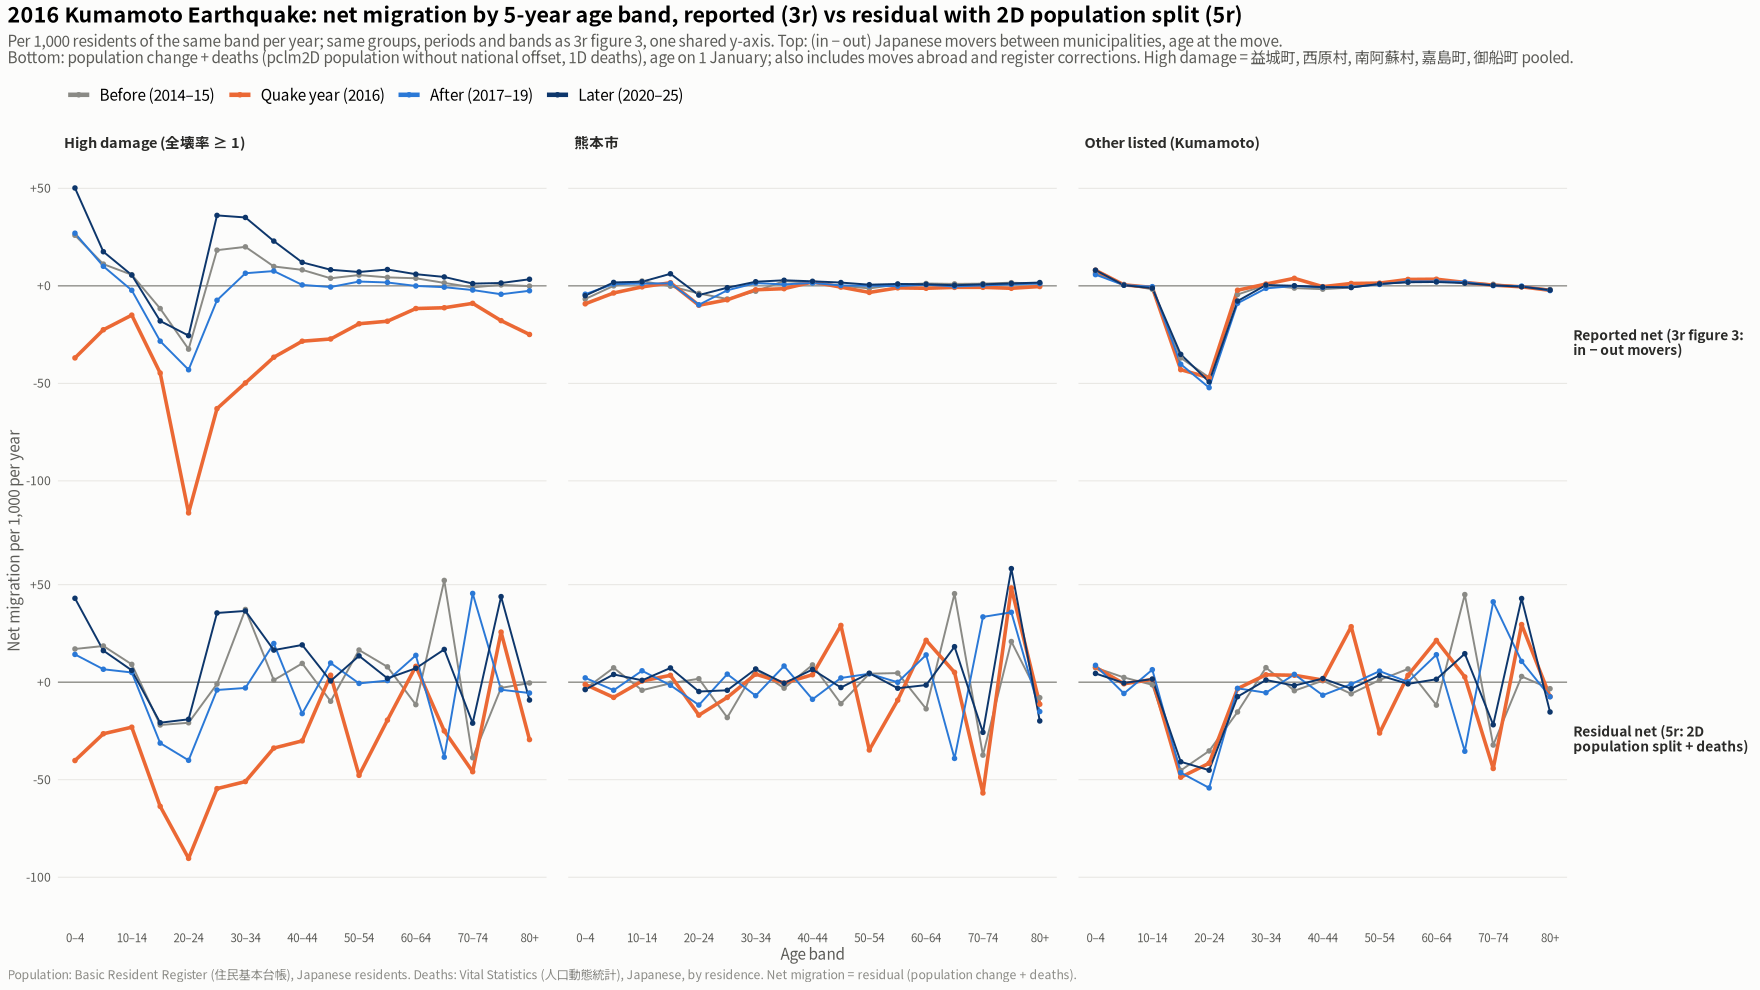

In [18]:
period_cols3 <- setNames(c("#8a8a85", "#eb6834", "#2a78d6", "#0d366b"), periods3)
p8 <- ggplot(cmp3, aes(band, rate, colour = period, group = period)) +
  geom_hline(yintercept = 0, colour = ink3, linewidth = 0.4) +
  geom_line(aes(linewidth = period == periods3[2])) +
  geom_point(size = 1.1) +
  facet_grid(source ~ group, labeller = labeller(source = label_wrap_gen(28))) +
  scale_colour_manual(values = period_cols3, name = NULL) +
  scale_linewidth_manual(values = c(`FALSE` = 0.6, `TRUE` = 1.1), guide = "none") +
  scale_x_discrete(labels = function(b) ifelse(seq_along(b) %% 2 == 1, sub("_", "–", b), "")) +
  scale_y_continuous(labels = function(v) sprintf("%+g", v)) +
  labs(title = "2016 Kumamoto Earthquake: net migration by 5-year age band, reported (3r) vs residual with 2D population split (5r)",
       subtitle = paste0("Per 1,000 residents of the same band per year; same groups, periods and bands as 3r figure 3, one shared y-axis. ",
                         "Top: (in − out) Japanese movers between municipalities, age at the move.\n",
                         "Bottom: population change + deaths (pclm2D population without national offset, 1D deaths), age on 1 January; also includes moves abroad and register corrections. ",
                         "High damage = 益城町, 西原村, 南阿蘇村, 嘉島町, 御船町 pooled."),
       x = "Age band", y = "Net migration per 1,000 per year", caption = src_note) +
  base_theme() +
  theme(axis.text.x = element_text(size = 7.5), strip.text.y = element_text(angle = 0, hjust = 0, size = 9)) +
  guides(colour = guide_legend(override.aes = list(linewidth = 1.4)))
show_save(p8, "08_kumamoto_age_profile_reported_vs_2d", width = 17, height = 8.5)

## Figures 9–10: what the 2D fits look like (Kumamoto)

Three listed municipalities of very different size: 熊本市 (~730k), 益城町 (~35k) and 五木村 (~1.2k).

- **Figure 9, Lexis surfaces:** single-year population by age (y) and count year (x), as each single age's share of that year's population (‰). A birth cohort moves along a diagonal, one year of age per year.
  - **Guide lines:** the 1947 cohort (start of the baby boom) and the 1966 cohort (丙午, a one-year dip).
  - **Rows:**
    - top: the 2D fit with the national single-year shape as offset (counts 2011–2021, used in figures 1–7);
    - bottom: the 2D fit without it (counts 2011–2026, used in figure 8).
  - **How to read it:** with the offset, the cliffs show as sharp diagonals. Without it they're smoothed into the 5-year band structure.
- **Figure 10, one year:** the 2016-01-01 count (baseline). Published 5-year bands are drawn as bars (people per year of age), with the three single-year fits (1D from 4r, 2D with offset, 2D without) as lines. All three keep every band total exactly; they differ only within bands.

fit_type,short,lambda_age,lambda_time
<chr>,<fct>,<dbl>,<dbl>
2D with national shape (2011–2021),熊本市,13700,100000
2D with national shape (2011–2021),益城町,100000,100000
2D with national shape (2011–2021),五木村,3000,100000
2D without national shape (2011–2026),熊本市,394,30000
2D without national shape (2011–2026),益城町,298,47600
2D without national shape (2011–2026),五木村,21900,100000


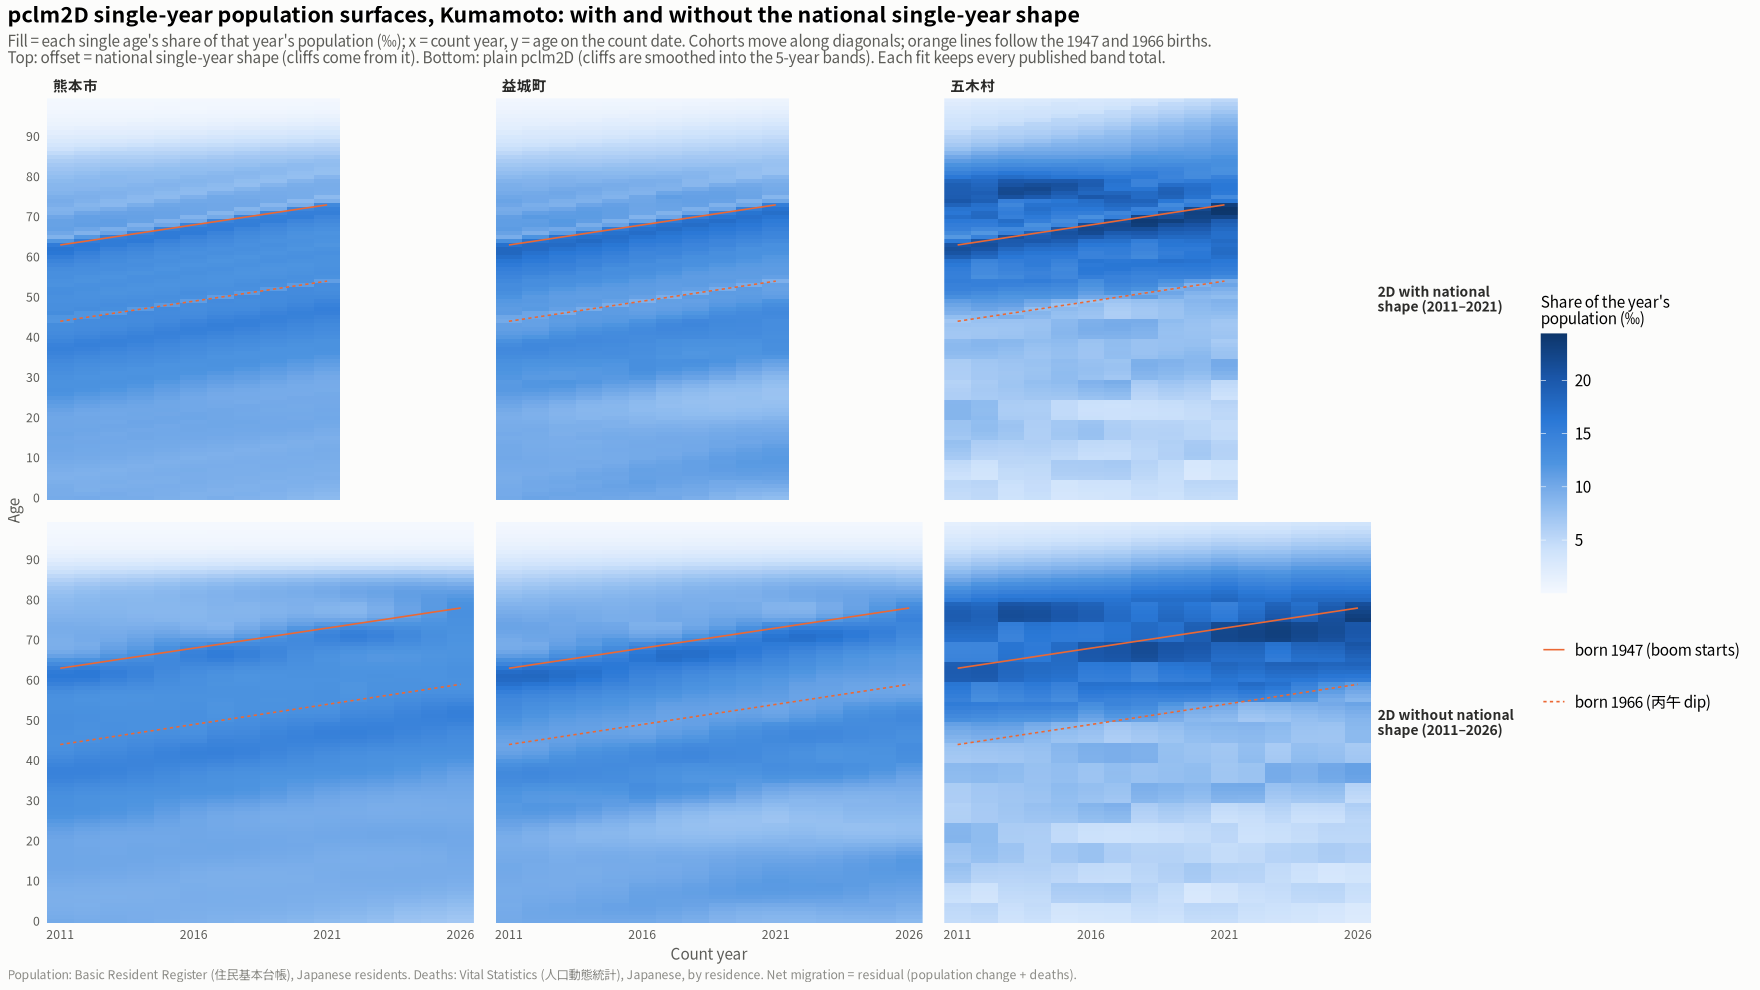

In [19]:
show3 <- study |> filter(short %in% c("熊本市", "益城町", "五木村")) |>
  mutate(short = factor(short, levels = c("熊本市", "益城町", "五木村")))
fit_lab <- c(off = "2D with national shape (2011–2021)", nooff = "2D without national shape (2011–2026)")
surf <- bind_rows(
  fits2d |> filter(code %in% show3$code) |> select(code, year, age, fit) |> mutate(fit_type = fit_lab[["off"]]),
  fk$pop |> filter(code %in% show3$code) |> select(code, year, age, fit) |> mutate(fit_type = fit_lab[["nooff"]])) |>
  filter(age <= 99) |>
  group_by(fit_type, code, year) |> mutate(share = 1000 * fit / sum(fit)) |> ungroup() |>
  left_join(show3 |> select(code, short), by = "code") |>
  mutate(fit_type = factor(fit_type, levels = unname(fit_lab)))

# smoothing chosen by BIC for these municipalities
bind_rows(fits2d |> filter(code %in% show3$code) |> distinct(code, lambda_age, lambda_time) |> mutate(fit_type = fit_lab[["off"]]),
          fk$pop |> filter(code %in% show3$code) |> distinct(code, lambda_age, lambda_time) |> mutate(fit_type = fit_lab[["nooff"]])) |>
  left_join(show3 |> select(code, short), by = "code") |>
  mutate(across(starts_with("lambda"), ~ signif(.x, 3))) |>
  select(fit_type, short, lambda_age, lambda_time) |> arrange(fit_type, short) |> as.data.frame()

# cohort guides: age on the count date = year - birth year - 1 (1 January counts)
guides_c <- bind_rows(
  expand_grid(birth = c(1947, 1966), year = 2011:2021, fit_type = fit_lab[["off"]]),
  expand_grid(birth = c(1947, 1966), year = 2011:2026, fit_type = fit_lab[["nooff"]])) |>
  mutate(age = year - birth - 1, label = ifelse(birth == 1947, "born 1947 (boom starts)", "born 1966 (丙午 dip)"),
         fit_type = factor(fit_type, levels = unname(fit_lab)))

p9 <- ggplot(surf, aes(year, age, fill = share)) +
  geom_raster() +
  geom_line(data = guides_c, aes(year, age, group = interaction(birth, fit_type), linetype = label), inherit.aes = FALSE,
            colour = "#eb6834", linewidth = 0.5) +
  facet_grid(fit_type ~ short, scales = "free_x", space = "free_x", labeller = labeller(fit_type = label_wrap_gen(22))) +
  scale_fill_gradientn(colours = c("#f4f8fe", "#cde2fb", "#8fbcef", "#4d94e0", "#2a78d6", "#1a56a8", "#0d366b"),
                       name = "Share of the year's\npopulation (‰)") +
  scale_linetype_manual(values = c("born 1947 (boom starts)" = "solid", "born 1966 (丙午 dip)" = "22"), name = NULL) +
  scale_x_continuous(breaks = seq(2011, 2026, 5), expand = c(0, 0)) +
  scale_y_continuous(breaks = seq(0, 100, 10), expand = c(0, 0)) +
  labs(title = "pclm2D single-year population surfaces, Kumamoto: with and without the national single-year shape",
       subtitle = paste0("Fill = each single age's share of that year's population (‰); x = count year, y = age on the count date. Cohorts move along diagonals; orange lines follow the 1947 and 1966 births.\n",
                         "Top: offset = national single-year shape (cliffs come from it). Bottom: plain pclm2D (cliffs are smoothed into the 5-year bands). Each fit keeps every published band total."),
       x = "Count year", y = "Age", caption = src_note) +
  base_theme() +
  theme(panel.grid.major.y = element_blank(), legend.position = "right", legend.justification = "center",
        legend.key.height = unit(1.2, "cm"), strip.text.y = element_text(angle = 0, hjust = 0, size = 9))
show_save(p9, "09_kumamoto_2d_surfaces", width = 17, height = 10)

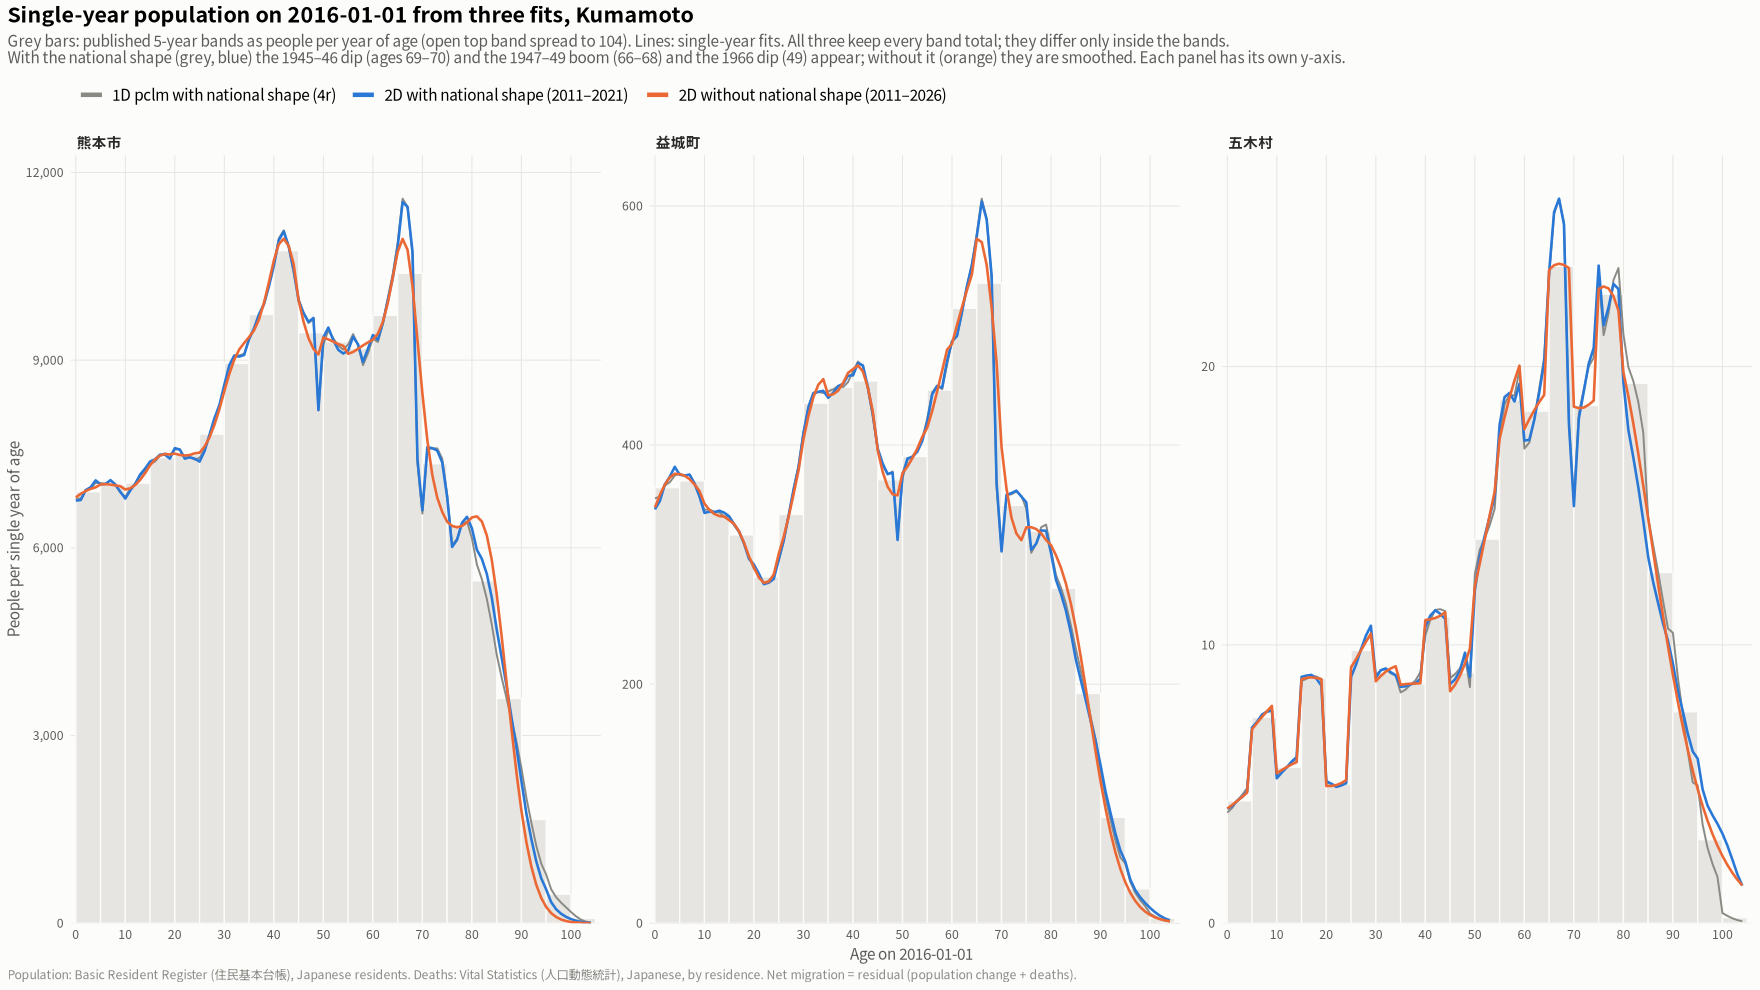

In [20]:
yr <- 2016
bars16 <- pop5 |> filter(code %in% show3$code, year == yr) |>
  group_by(code) |> group_modify(function(g, k) band_table(g$age_band, g$n)) |> ungroup() |>
  mutate(per_year = n / (upper - lower)) |>
  left_join(show3 |> select(code, short), by = "code")
lines16 <- bind_rows(
  fits1d |> filter(series == "pop", code %in% show3$code, year == yr) |> select(code, age, fit) |> mutate(fit_type = "1D pclm with national shape (4r)"),
  fits2d |> filter(code %in% show3$code, year == yr) |> select(code, age, fit) |> mutate(fit_type = fit_lab[["off"]]),
  fk$pop |> filter(code %in% show3$code, year == yr) |> select(code, age, fit) |> mutate(fit_type = fit_lab[["nooff"]])) |>
  left_join(show3 |> select(code, short), by = "code") |>
  mutate(fit_type = factor(fit_type, levels = c("1D pclm with national shape (4r)", unname(fit_lab))))

p10 <- ggplot() +
  geom_rect(data = bars16, aes(xmin = lower, xmax = upper, ymin = 0, ymax = per_year),
            fill = "#e6e5e1", colour = surface, linewidth = 0.4) +
  geom_line(data = lines16, aes(age, fit, colour = fit_type, linewidth = fit_type)) +
  facet_wrap(~short, ncol = 3, scales = "free_y") +
  scale_colour_manual(values = setNames(c("#8a8a85", "#2a78d6", "#eb6834"), levels(lines16$fit_type)), name = NULL) +
  scale_linewidth_manual(values = setNames(c(0.6, 0.8, 0.8), levels(lines16$fit_type)), guide = "none") +
  scale_x_continuous(breaks = seq(0, 100, 10), expand = expansion(mult = 0.01)) +
  scale_y_continuous(labels = scales::label_comma(), expand = expansion(mult = c(0, 0.06))) +
  labs(title = "Single-year population on 2016-01-01 from three fits, Kumamoto",
       subtitle = paste0("Grey bars: published 5-year bands as people per year of age (open top band spread to 104). Lines: single-year fits. ",
                         "All three keep every band total; they differ only inside the bands.\n",
                         "With the national shape (grey, blue) the 1945–46 dip (ages 69–70) and the 1947–49 boom (66–68) and the 1966 dip (49) appear; without it (orange) they are smoothed. ",
                         "Each panel has its own y-axis."),
       x = "Age on 2016-01-01", y = "People per single year of age", caption = src_note) +
  base_theme() +
  theme(panel.grid.major.x = element_line(colour = grid_col, linewidth = 0.3)) +
  guides(colour = guide_legend(override.aes = list(linewidth = 1.4)))
show_save(p10, "10_kumamoto_2016_single_year_fits", width = 17, height = 6.5)

## Figure 11: residual (2D) vs reported net migration, Kumamoto 2014–2020

4r figure 6 (`res/4r_06_kumamoto_residual_vs_reported.png`) redone with the 2D population split. The cells are the same: municipality × baseline cohort bin × calendar year, per 1,000 per year.

- **Reported:** (in − out) Japanese movers between municipalities, from the 1D mover splits with the same Lexis rule (`val` from figure 3).
- **Residual:** population change + deaths, with the population split by `pclm2D` with the national offset.

Dotted diagonals mark residual − reported = ±5 and ±10 per 1,000 (±0.5 and ±1 percentage points); horizontal lines mark residual = ±5 and ±10.

The table gives the 4r summary for both splits, so the two figures can be compared number by number.


method,group,points,correlation,mean_residual,mean_reported,mean_difference
<chr>,<fct>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
1D pclm (4r),High damage (全壊率 ≥ 1),420,0.832,-2.7,-3.0,0.3
2D pclm2D,High damage (全壊率 ≥ 1),420,0.845,-3.6,-3.0,-0.7
1D pclm (4r),熊本市,84,0.564,-0.4,-0.5,0.2
2D pclm2D,熊本市,84,0.616,0.1,-0.5,0.6
1D pclm (4r),Other listed (Kumamoto),3276,0.703,-3.8,-3.9,0.1
2D pclm2D,Other listed (Kumamoto),3276,0.720,-4.4,-3.9,-0.5


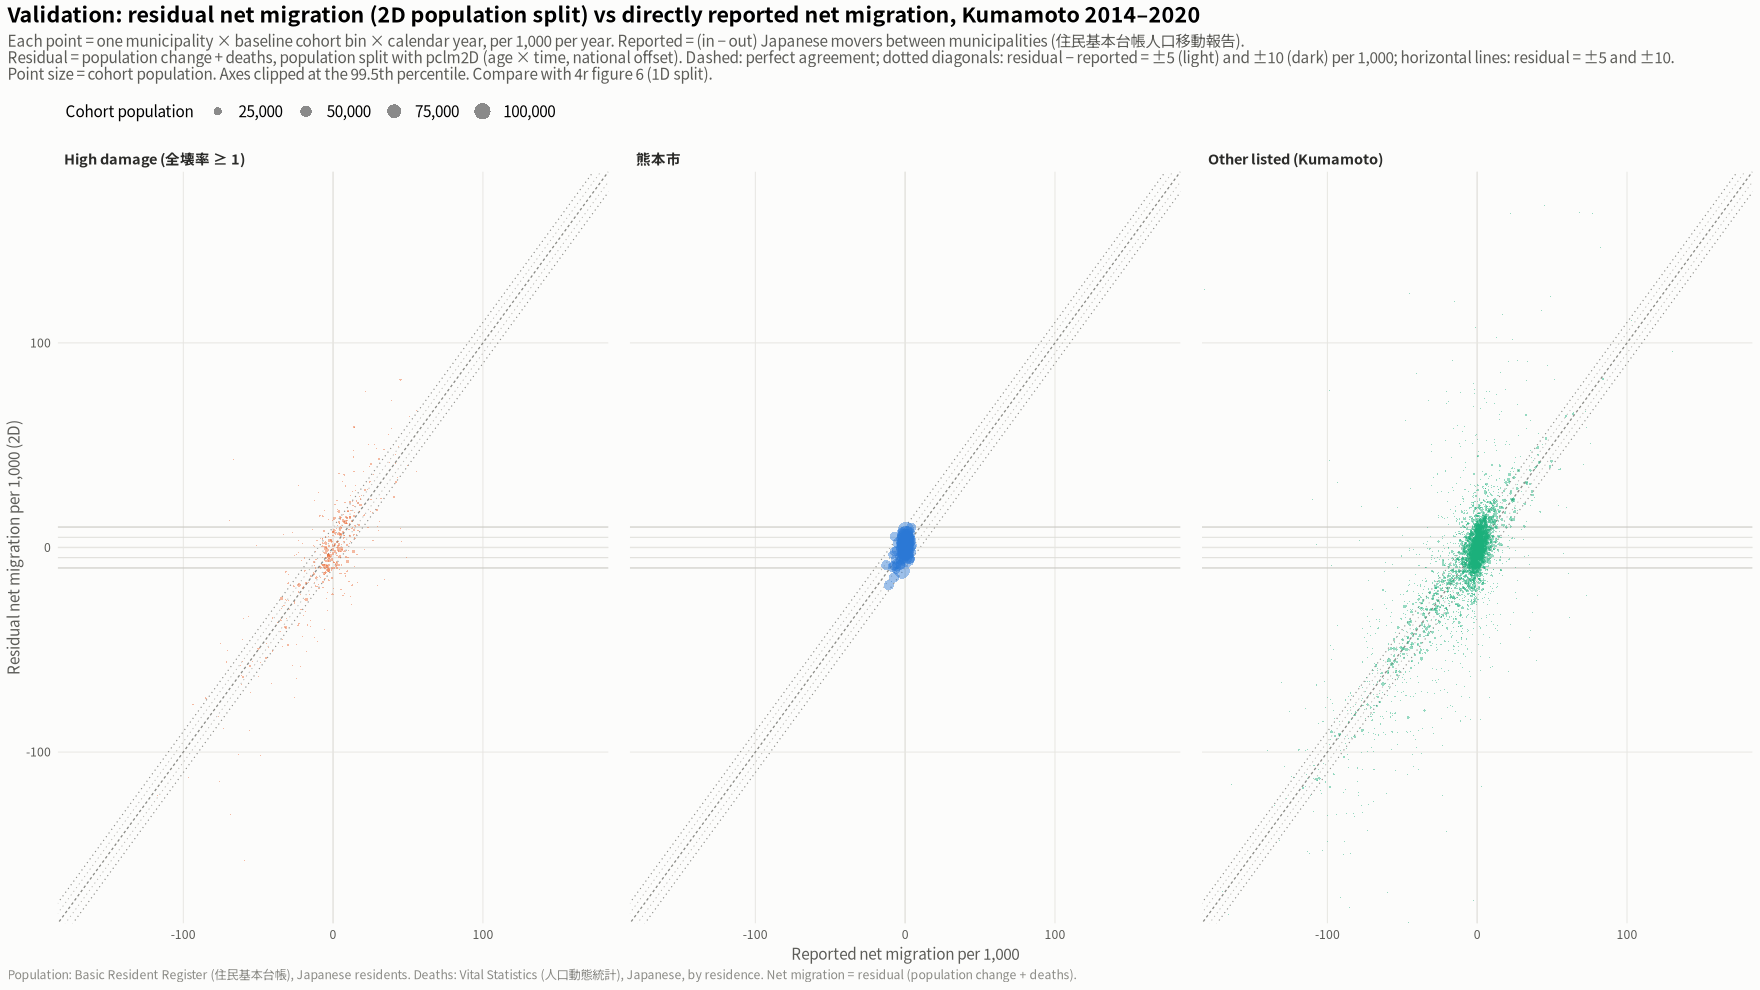

In [21]:
# 4r section 6 summary, 1D and 2D side by side
val |>
  mutate(group = factor(group, levels = group_levels$kumamoto)) |>
  group_by(method, group) |>
  summarise(points = n(), correlation = round(cor(residual, reported), 3),
            mean_residual = round(weighted.mean(residual, P0), 1),
            mean_reported = round(weighted.mean(reported, P0), 1),
            mean_difference = round(weighted.mean(residual - reported, P0), 1), .groups = "drop") |>
  arrange(group, method) |>
  as.data.frame()

val2 <- val |> filter(method == "2D pclm2D") |>
  mutate(group = factor(group, levels = group_levels$kumamoto))
lim <- quantile(abs(c(val2$residual, val2$reported)), 0.995)
p11 <- ggplot(val2, aes(reported, residual, colour = group)) +
  # reference lines at +-5 and +-10 per 1,000: horizontal (residual) and diagonal (residual - reported)
  geom_hline(yintercept = c(-10, 10), colour = "#c9c8c3", linewidth = 0.35) +
  geom_hline(yintercept = c(-5, 5), colour = "#dcdbd6", linewidth = 0.3) +
  geom_abline(slope = 1, intercept = c(-10, 10), colour = "#8a8a85", linewidth = 0.35, linetype = "dotted") +
  geom_abline(slope = 1, intercept = c(-5, 5), colour = "#b5b4af", linewidth = 0.3, linetype = "dotted") +
  geom_abline(slope = 1, intercept = 0, colour = ink3, linewidth = 0.4, linetype = "22") +
  geom_hline(yintercept = 0, colour = grid_col) + geom_vline(xintercept = 0, colour = grid_col) +
  geom_point(aes(size = P0), alpha = 0.45, stroke = 0) +
  facet_wrap(~group, nrow = 1) +
  scale_colour_manual(values = group_cols[group_levels$kumamoto], guide = "none") +
  scale_size_area(max_size = 5, name = "Cohort population", labels = scales::label_comma()) +
  coord_cartesian(xlim = c(-lim, lim), ylim = c(-lim, lim)) +
  labs(title = "Validation: residual net migration (2D population split) vs directly reported net migration, Kumamoto 2014–2020",
       subtitle = paste0("Each point = one municipality × baseline cohort bin × calendar year, per 1,000 per year. ",
                         "Reported = (in − out) Japanese movers between municipalities (住民基本台帳人口移動報告).\n",
                         "Residual = population change + deaths, population split with pclm2D (age × time, national offset). ",
                         "Dashed: perfect agreement; dotted diagonals: residual − reported = ±5 (light) and ±10 (dark) per 1,000; horizontal lines: residual = ±5 and ±10.\nPoint size = cohort population. Axes clipped at the 99.5th percentile. Compare with 4r figure 6 (1D split)."),
       x = "Reported net migration per 1,000", y = "Residual net migration per 1,000 (2D)", caption = src_note) +
  base_theme() +
  theme(panel.grid.major.x = element_line(colour = grid_col, linewidth = 0.3))
show_save(p11, "11_kumamoto_residual_vs_reported_2d", width = 16, height = 6.5)
